# Trabalho final: Modelos de recomendação e análise de espaços latentes

**Disciplina:** *Aprendizado não-supervisionado* - *MC847*\
**Instituição:** *Universidade Estadual de Campinas*\
**Professor(a):** *Marcos Medeiros Raimundo*\
**Semestre:** *2s2026*

| Nome | RA |
|---|---|
| Gustavo Marcelino Rodrigues | 238183 |
| Lucas Lembo de Lara | 254467 |
| Mateus Farha Ribeiro | 252678 |

## Introdução

Em sistemas de recomendação, a principal tarefa é aprender a preferência de um usuário a partir de um histórico parcial de interações.
Isso pode ser visto como um problema de *completar informação*: dado o histórico parcial de um usuário, quais itens provavelmente faltam?
Neste trabalho vocês vão prever notas não observadas com modelos que fazem suposições diferentes sobre essa estrutura e, depois, investigar o que o espaço aprendido contém e quais suposições o produziram.

O trabalho é dividido em três etapas, sendo as duas primeiras comuns a todos os grupos e a terceira a ser definida por cada grupo.
A primeira etapa consiste em definir uma baseline que será usada como referência para as demais etapas.
A segunda consiste em realizar e analisar experimentos para entender como diferentes suposições sobre a estrutura latente dos dados afetam o desempenho do modelo.
A última etapa é a contribuição de cada grupo para o problema, que pode ser uma proposta de melhoria do modelo ou uma análise mais profunda de algum aspecto do problema.

As duas primeiras etapas têm códigos de referência, que podem ser usados como base para a implementação dos modelos.
Vocês podem usar bibliotecas externas com implementações de modelos, mas devem deixar claro quais bibliotecas foram usadas e como elas foram usadas.
Por exemplo, vocês podem reescrever o modelo de fatoração de matrizes em PyTorch ou Jax para melhorar a performance, desde que justifiquem a escolha e expliquem como a implementação foi mantida fiel ao modelo original.

## Dataset

Utilizaremos o conjunto de dados MovieLens 100K [(Harper e Konstan, 2015)](https://www.scirp.org/reference/referencespapers?referenceid=3586299): 100 mil notas inteiras de 1 a 5, dadas por 943 usuários a 1.682 filmes, com pelo menos 20 notas por usuário.
A matriz tem densidade de cerca de 6%, cada usuário tem idade (em anos), gênero e ocupação (21 categorias) e cada filme tem título, ano e 19 indicadores de gênero, e um filme pode ter vários gêneros.

Devido à natureza do problema, a ausência de notas não pode ser tratada como aleatória: Os motivos pelos quais um usuário não avaliou um item podem ser variados, incluindo falta de interesse, falta de exposição ao item ou simplesmente esquecimento.
Isso significa que os dados de treinamento são enviesados e não representam a distribuição real de preferências dos usuários.

In [1]:
import random
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from numpy.typing import NDArray

sns.set_theme(style="whitegrid")

SEED = 42
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
MOVIELENS_URL = "https://files.grouplens.org/datasets/movielens/ml-100k.zip"
DATA_DIR = "./data/"

def set_seed(seed: int) -> None:
    """Set the random seed for reproducibility."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

In [2]:
from pandas.core.frame import DataFrame

GENRES = [
    "unknown", "Action", "Adventure", "Animation", "Children's", "Comedy",
    "Crime", "Documentary", "Drama", "Fantasy", "Film-Noir", "Horror",
    "Musical", "Mystery", "Romance", "Sci-Fi", "Thriller", "War", "Western"
]


def load_movielens() -> tuple[DataFrame, DataFrame, DataFrame]:
    """Download and extract the MovieLens dataset."""
    import zipfile

    import requests

    data_dir = Path(DATA_DIR)
    data_dir.mkdir(parents=True, exist_ok=True)

    zip_path = data_dir / "ml-100k.zip"
    target_dir = data_dir / "ml-100k"

    if not target_dir.exists():
        if not zip_path.exists():
            print("Downloading MovieLens dataset...")
            response = requests.get(MOVIELENS_URL)

            with open(zip_path, "wb") as f:
                f.write(response.content)

            print("Download complete.")

        print("Extracting MovieLens dataset...")
        with zipfile.ZipFile(zip_path) as zip_ref:
            zip_ref.extractall(data_dir)

        print(f"Extracted to {data_dir}.")

    ratings = pd.read_csv(
            target_dir / "u.data",
            sep="\t",
            names=["user_id", "item_id", "rating", "timestamp"],
            dtype={"user_id": np.int32, "item_id": np.int32, "rating": np.float32, "timestamp": np.int64},
        )

    users = pd.read_csv(
            target_dir / "u.user",
            sep="|",
            names=["user_id", "age", "gender", "occupation", "zip_code"],
            dtype={"user_id": np.int32, "age": np.int32, "gender": str, "occupation": str, "zip_code": str},
        )

    item_cols = ["item_id", "title", "release_date", "video_release_date", "imdb_url", *GENRES]

    movies = pd.read_csv(
        target_dir / "u.item",
        sep="|",
        encoding="latin-1",
        names=item_cols,
        usecols=["item_id", "title", "release_date", *GENRES],
        dtype={"item_id": np.int32, "title": str, "release_date": str},
    )

    movies["year"] = pd.to_numeric(movies["title"].str.extract(r"\((\d{4})\)")[0], errors="coerce")

    movies["genres"] = movies[GENRES].apply(
        lambda row: "|".join([g for g in GENRES if row[g] == 1]), axis=1
    )

    # Normalização para que os IDs de usuário e item comecem em 0
    ratings["user_id"] -= 1
    ratings["item_id"] -= 1
    users["user_id"] -= 1
    movies["item_id"] -= 1

    return ratings, users, movies


def ratings_to_matrix(ratings: pd.DataFrame, fill_value: float = float("nan")) -> NDArray[np.float64]:
    """Convert ratings DataFrame to a user-item matrix."""
    num_users = ratings["user_id"].max() + 1
    num_items = ratings["item_id"].max() + 1

    user_item_matrix = np.full((num_users, num_items), fill_value, dtype=np.float64)
    user_item_matrix[ratings["user_id"], ratings["item_id"]] = ratings["rating"].values.astype(np.float64)

    return user_item_matrix


In [3]:
ratings, users, movies = load_movielens()
density = len(ratings) / (len(users) * len(movies))
print(f"notas={len(ratings):,}; usuários={len(users):,}; filmes={len(movies):,}; densidade={density:.3f}")

notas=100,000; usuários=943; filmes=1,682; densidade=0.063


## Formulação do problema

Uma suposição comum em sistemas de recomendação é que a preferência de um usuário por um item pode ser representada como uma função sobre um espaço latente compartilhado entre usuários e itens.
Ou seja, considerando que cada usuário e cada item podem ser representados como vetores em um espaço latente, a nota de um usuário para um item pode ser modelada como uma função que mede a compatibilidade entre os vetores do usuário e do item.

Utilizaremos uma formulação geral para este problema, que pode acomodar diferentes modelos e suposições sobre como os vetores latentes são gerados e como a função de compatibilidade é definida.
Considere um conjunto de usuários $U$ e um conjunto de itens $I$, e seja $R$ a matriz de notas, a nota do usuário $u$ para o item $i$, $R_{ui}$ é modelada como:

$$
R_{ui} = \mu + b_u + b_i + f(\mathbf{z}_u, \mathbf{w}_i) + \epsilon_{ui}
$$
onde $\mu$ é a média global das notas, $b_u$ e $b_i$ são os *biases* do usuário e do item, respectivamente, $\mathbf{z}_u$ e $\mathbf{w}_i$ são os vetores latentes do usuário e do item, $f$ é a função de compatibilidade entre os vetores latentes e $\epsilon_{ui}$ é o erro de modelagem para aquele par usuário-item.

Um desafio importante é que a matriz de notas $R$ é muito esparsa, ou seja, grande parte dos pares usuário-item não possuem notas observadas. Isso significa que aprender a estrutura latente compartilhada pode ser difícil sem fazer suposições adicionais sobre como os vetores latentes são gerados e como a função de compatibilidade é definida.

Vamos explorar como diferentes suposições afetam o desempenho do modelo e o que podemos aprender sobre a estrutura latente dos dados através da inspeção do espaço latente aprendido.

> **Importante:** Os modelos têm uma abordagem transdutiva, ou seja, eles aprendem os vetores latentes apenas para os usuários e itens presentes no conjunto de treinamento.
As features de um usuário não são as notas que ele deu, mas sim apenas um identificador único, e o mesmo vale para os itens.
Isso permite que o modelo possua parâmetros específicos para cada usuário, mas também significa que ele não pode generalizar para novos usuários ou itens sem re-treinamento.

## Diretrizes para o trabalho

Para cada experimento, sigam as seguintes diretrizes:

> 1. Escrevam a hipótese e a previsão **antes** de rodar cada experimento.
> 2. Resultados negativos ou inconclusivos valem, se vierem com **análise crítica**.
> 3. Todos os modelos, inclusive os mais simples, passam pelo mesmo protocolo (a seguir).
> 4. Separem o que um resultado diz sobre a previsão do que ele diz sobre a representação latente.
> 5. Citem fontes sempre que necessário, seja para motivar uma escolha, ou para justificar uma decisão.

A nota não depende da métrica obtida pelo modelo, mas da qualidade das hipóteses, aplicação correta do protocolo e da análise das evidências a favor, contra ou insuficientes.

### Protocolo experimental

Os experimentos devem ser controlados, com uma variável de interesse por vez e com o mesmo protocolo:

**Split dos dados.** O conjunto de dados deve ser dividido em treino e teste, com 80% das notas para treino e 20% para teste.
A divisão deve ser feita de forma estratificada por usuário, garantindo que cada usuário tenha pelo menos uma nota em cada conjunto, e todo filme deve ter pelo menos uma nota no conjunto de treino.

**Métricas.** RMSE (principal) e MAE, com previsões truncadas em $[1,5]$, e NLL quando o modelo define uma verossimilhança comparável.

**Seleção de hiperparâmetros.** O conjunto de teste é usado uma única vez, para reportar o desempenho final.
Os hiperparâmetros (dimensão latente, regularização, variância do ruído, número de épocas e assim por diante) são escolhidos por *cross-validation* com $K$ folds dentro do conjunto de treino, respeitando as mesmas restrições da divisão de treino e teste.
Depois da escolha, o modelo é treinado com todo o treino e avaliado no teste.

**Incerteza.** Compare resultados com **intervalos de confiança** sobre as métricas.
Vocês podem usar *cross-validation*, reportando a média e o desvio padrão das métricas entre os folds, que refletem a variação causada pelos dados de treino e pela inicialização, ou *bootstrapping*, amostrando com reposição o conjunto de teste e reportando a média e o intervalo de percentis de 95%, que reflete a variação da amostra de teste.

In [4]:
def split_ratings(
    ratings: pd.DataFrame,
    test_frac: float = 0.2,
    seed: int = 0,
) -> tuple[pd.DataFrame, pd.DataFrame]:
    df = (
        ratings.sample(frac=1, random_state=seed)
               .sort_values("user_id", kind="stable")
               .reset_index(drop=True)
    )

    grouped = df.groupby("user_id")
    pos = (
        grouped.cumcount() /
        grouped["user_id"].transform("count")
    ).to_numpy()

    splits = np.zeros(len(df), dtype=np.int8)
    splits[pos >= (1 - test_frac)] = 1

    # Trocar a primeira aparição de cada filme para o conjunto de treino
    first_appearance = df.groupby("item_id").head(1).index
    splits[first_appearance] = 0

    train_df = df.iloc[splits == 0]
    test_df = df.iloc[splits == 1]

    return train_df, test_df

In [5]:
from typing import Protocol

from sklearn.decomposition import PCA
from sklearn.metrics import (
    mean_absolute_error,
    root_mean_squared_error,
)

# Funções auxiliares

def clip_ratings(prediction: NDArray[np.float64]) -> NDArray[np.float64]:
    return np.clip(np.asarray(prediction, dtype=np.float64), 1.0, 5.0)


class Model(Protocol):
    def fit(self, train_df: DataFrame) -> None: ...

    def predict(
        self, user_id: NDArray[np.intp], item_id: NDArray[np.intp],
    ) -> NDArray[np.float64]: ...


class ProbabilisticModel(Model, Protocol):
    def predict_log_proba(
        self,
        user_id: NDArray[np.intp],
        item_id: NDArray[np.intp],
        ratings: NDArray[np.float64],
    ) -> NDArray[np.float64]: ...


def evaluate_model(
    model: Model | ProbabilisticModel, **dfs: DataFrame
) -> dict[str, float]:
    metrics: dict[str, float] = {}
    
    for name, df in dfs.items():
        users = df["user_id"].to_numpy(dtype=np.intp)
        items = df["item_id"].to_numpy(dtype=np.intp)
        ratings = df["rating"].to_numpy(dtype=np.float64)

        preds = model.predict(users, items)
        preds_clipped = clip_ratings(preds)

        metrics |= {
            f"{name}_rmse": root_mean_squared_error(ratings, preds_clipped),
            f"{name}_mae": mean_absolute_error(ratings, preds_clipped),
            # Vocês podem adicionar mais métricas aqui
        }

        if hasattr(model, "predict_log_proba"):
            log_proba = model.predict_log_proba(users, items, ratings)
            metrics[f"{name}_nll"] = float(-np.mean(log_proba))

    return metrics



In [6]:
train_df, test_df = split_ratings(ratings, seed=SEED)

In [7]:
# Explorem os dados, plotem gráficos, calculem estatísticas, para entender melhor o problema,
# os dados disponíveis, a distribuição das notas, a distribuição de usuários e itens, e assim por diante.

### Hipóteses da análise exploratória (escritas antes de rodar)

**H1 (nota mais comum).** Prevemos que a nota mais frequente é **4**, por estar entre 3 e 5.

**H2a (popularidade × direção da média).** Prevemos que filmes com **mais** avaliações têm nota média **menor**, porque mais avaliadores trazem opiniões mais diversas.

**H2b (popularidade × dispersão da média).** Prevemos que filmes com **poucas** avaliações têm médias mais **extremas** (altas ou baixas), porque uma única nota pesa muito na média.

O que refutaria as hipóteses seria outra nota mais frequente que 4 (H1), uma correlação positiva entre popularidade e nota média (H2a) e uma dispersão das médias parecida entre as faixas de popularidade (H2b).

Distribuição empírica das notas (proporção):
rating
1.0    0.061
2.0    0.114
3.0    0.271
4.0    0.342
5.0    0.212
Média = 3.530; desvio padrão = 1.126

Notas por usuário: {'count': 943.0, 'mean': 106.0, 'std': 100.9, 'min': 20.0, '25%': 33.0, '50%': 65.0, '75%': 148.0, 'max': 737.0}
Notas por filme:   {'count': 1682.0, 'mean': 59.5, 'std': 80.4, 'min': 1.0, '25%': 6.0, '50%': 27.0, '75%': 80.0, 'max': 583.0}
Os 10% filmes mais avaliados (168) concentram 42.7% das notas.
Filmes com menos de 5 notas: 333 de 1682


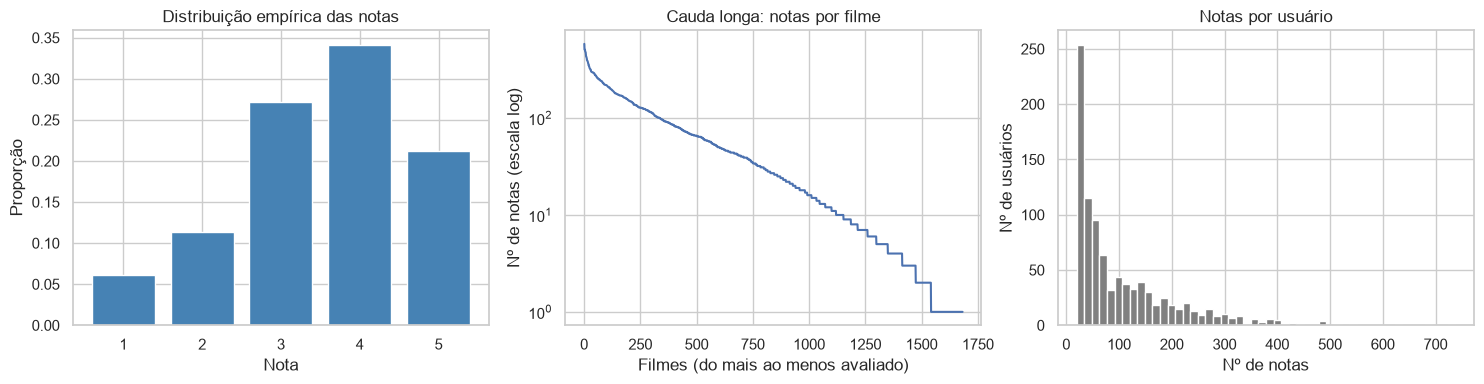

In [8]:
from scipy.stats import spearmanr

# Pasta onde salvamos as figuras que vão para o relatório
FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)

# Proporção de cada nota (1 a 5) no conjunto inteiro, que é a distribuição empírica
dist_notas = ratings["rating"].value_counts(normalize=True).sort_index()
print("Distribuição empírica das notas (proporção):")
print(dist_notas.round(3).to_string())
print(f"Média = {ratings['rating'].mean():.3f}; desvio padrão = {ratings['rating'].std():.3f}")

# Quantas notas cada usuário deu e quantas cada filme recebeu, para enxergar a cauda longa
n_por_usuario = ratings.groupby("user_id").size()
n_por_filme = ratings.groupby("item_id").size().sort_values(ascending=False)

print("\nNotas por usuário:", n_por_usuario.describe().round(1).to_dict())
print("Notas por filme:  ", n_por_filme.describe().round(1).to_dict())

# Fatia das notas que fica com os 10% de filmes mais avaliados
n_top = int(0.1 * len(n_por_filme))
frac_top = n_por_filme.iloc[:n_top].sum() / n_por_filme.sum()
print(f"Os 10% filmes mais avaliados ({n_top}) concentram {frac_top:.1%} das notas.")
print(f"Filmes com menos de 5 notas: {(n_por_filme < 5).sum()} de {len(n_por_filme)}")

# Gráficos da distribuição das notas, da cauda longa dos filmes e da atividade dos usuários
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].bar(dist_notas.index.astype(int), dist_notas.values, color="steelblue")
axes[0].set(title="Distribuição empírica das notas", xlabel="Nota", ylabel="Proporção")
axes[1].plot(np.arange(1, len(n_por_filme) + 1), n_por_filme.values)
axes[1].set(title="Cauda longa: notas por filme", xlabel="Filmes (do mais ao menos avaliado)",
            ylabel="Nº de notas (escala log)", yscale="log")
axes[2].hist(n_por_usuario, bins=50, color="gray")
axes[2].set(title="Notas por usuário", xlabel="Nº de notas", ylabel="Nº de usuários")
fig.tight_layout()
fig.savefig(FIG_DIR / "eda_notas_cauda_longa.png", dpi=150)
plt.show()

Spearman (nº de notas × média do filme): rho = 0.503, p-valor = 8.8e-109
         filmes  media_das_medias  desvio_das_medias
n_notas                                             
1-5         384             2.543              1.052
6-20        371             2.879              0.606
21-50       334             3.103              0.540
51-100      259             3.374              0.466
101-200     217             3.570              0.422
>200        117             3.798              0.359


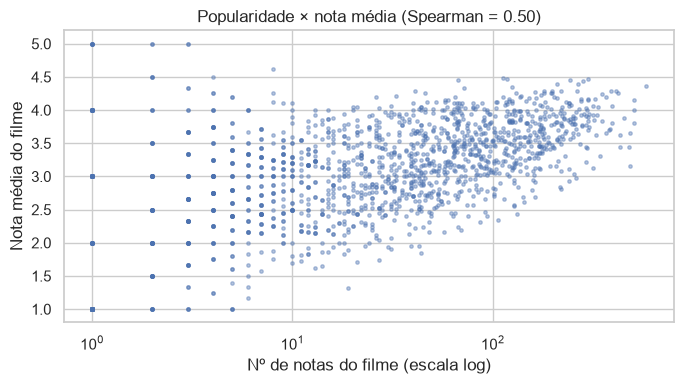

In [9]:
# Número de notas e nota média de cada filme
stats_filme = ratings.groupby("item_id")["rating"].agg(n_notas="size", media="mean")

# Spearman compara a ordem (ranking) das duas variáveis. Valor positivo quer dizer que filmes mais avaliados têm média maior
rho, p_valor = spearmanr(stats_filme["n_notas"], stats_filme["media"])
print(f"Spearman (nº de notas × média do filme): rho = {rho:.3f}, p-valor = {p_valor:.1e}")

# Agrupa os filmes por faixa de popularidade e compara a média e a dispersão das médias em cada faixa
faixas = pd.cut(
    stats_filme["n_notas"],
    bins=[0, 5, 20, 50, 100, 200, np.inf],
    labels=["1-5", "6-20", "21-50", "51-100", "101-200", ">200"],
)
resumo_faixas = stats_filme.groupby(faixas, observed=True)["media"].agg(
    filmes="size", media_das_medias="mean", desvio_das_medias="std"
)
print(resumo_faixas.round(3).to_string())

# Popularidade contra nota média de cada filme
fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(stats_filme["n_notas"], stats_filme["media"], s=6, alpha=0.4)
ax.set(xscale="log", xlabel="Nº de notas do filme (escala log)", ylabel="Nota média do filme",
       title=f"Popularidade × nota média (Spearman = {rho:.2f})")
fig.tight_layout()
fig.savefig(FIG_DIR / "eda_popularidade_media.png", dpi=150)
plt.show()

Gênero dos usuários: {'M': 670, 'F': 273}
Idade dos usuários: {'count': 943.0, 'mean': 34.1, 'std': 12.2, 'min': 7.0, '25%': 25.0, '50%': 31.0, '75%': 43.0, 'max': 73.0}
Ocupações (8 mais comuns): {'student': 196, 'other': 105, 'educator': 95, 'administrator': 79, 'engineer': 67, 'programmer': 66, 'librarian': 51, 'writer': 45}

Filmes por gênero (8 mais comuns): {'Drama': 725, 'Comedy': 505, 'Action': 251, 'Thriller': 251, 'Romance': 247, 'Adventure': 135, "Children's": 122, 'Crime': 109}
Filmes com mais de um gênero: 849 de 1682
Ano dos filmes: {'count': 1681.0, 'mean': 1989.0, 'std': 14.0, 'min': 1922.0, '25%': 1992.0, '50%': 1995.0, '75%': 1996.0, 'max': 1998.0}


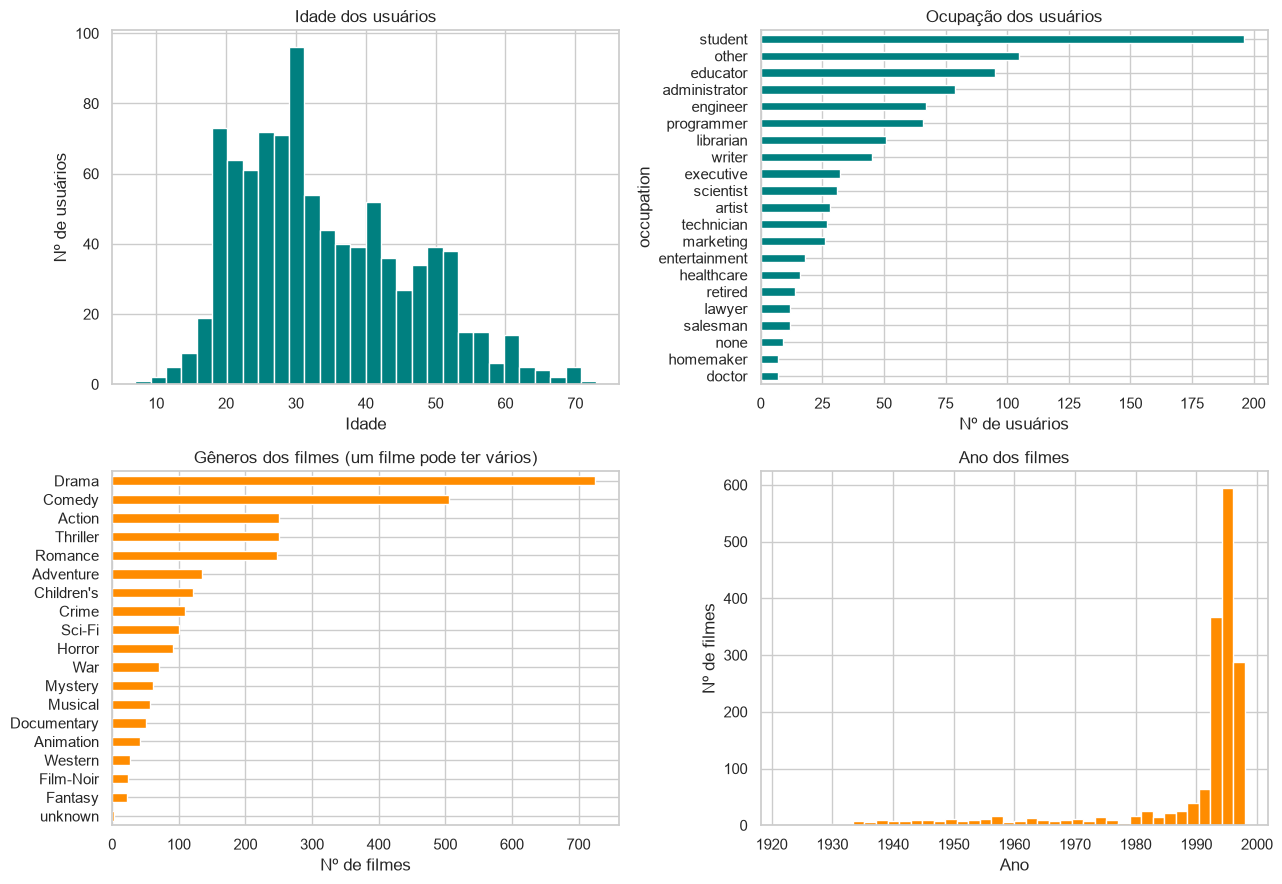

In [10]:
# Perfil dos usuários. 
print("Gênero dos usuários:", users["gender"].value_counts().to_dict())
print("Idade dos usuários:", users["age"].describe().round(1).to_dict())
print("Ocupações (8 mais comuns):", users["occupation"].value_counts().head(8).to_dict())

# Quantos filmes existem em cada gênero, lembrando que um filme pode ter vários
contagem_generos = movies[GENRES].sum().sort_values(ascending=False)
print("\nFilmes por gênero (8 mais comuns):", contagem_generos.head(8).to_dict())
print("Filmes com mais de um gênero:", int((movies[GENRES].sum(axis=1) > 1).sum()), "de", len(movies))
print("Ano dos filmes:", movies["year"].describe().round(0).to_dict())

# Histogramas e barras com o perfil de usuários e filmes
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
axes[0, 0].hist(users["age"], bins=30, color="teal")
axes[0, 0].set(title="Idade dos usuários", xlabel="Idade", ylabel="Nº de usuários")
users["occupation"].value_counts().sort_values().plot.barh(ax=axes[0, 1], color="teal")
axes[0, 1].set(title="Ocupação dos usuários", xlabel="Nº de usuários")
contagem_generos.sort_values().plot.barh(ax=axes[1, 0], color="darkorange")
axes[1, 0].set(title="Gêneros dos filmes (um filme pode ter vários)", xlabel="Nº de filmes")
axes[1, 1].hist(movies["year"].dropna(), bins=40, color="darkorange")
axes[1, 1].set(title="Ano dos filmes", xlabel="Ano", ylabel="Nº de filmes")
fig.tight_layout()
fig.savefig(FIG_DIR / "eda_metadados.png", dpi=150)
plt.show()

In [11]:
# Confere se o split 80/20 respeitou as regras do protocolo
print(f"Treino: {len(train_df):,} notas ({len(train_df) / len(ratings):.1%})")
print(f"Teste:  {len(test_df):,} notas ({len(test_df) / len(ratings):.1%})")
print("Todo usuário tem nota no treino?", train_df["user_id"].nunique() == len(users))
print("Todo usuário tem nota no teste? ", test_df["user_id"].nunique() == len(users))
print("Todo filme tem nota no treino?  ", train_df["item_id"].nunique() == len(movies))
print("Filmes sem nenhuma nota no teste:", len(movies) - test_df["item_id"].nunique())
print(f"Nota média no treino: {train_df['rating'].mean():.3f}; no teste: {test_df['rating'].mean():.3f}")

Treino: 80,696 notas (80.7%)
Teste:  19,304 notas (19.3%)
Todo usuário tem nota no treino? True
Todo usuário tem nota no teste?  False
Todo filme tem nota no treino?   True
Filmes sem nenhuma nota no teste: 333
Nota média — treino: 3.529; teste: 3.532


**Discussão (EDA)**
- **H1 confirmada.** A nota 4 é a mais frequente (34,2%). A média (3,53) fica acima do centro da escala, o que sugere que os usuários avaliam filmes que escolheram assistir.
- **H2a refutada.** A correlação entre popularidade e nota média é positiva (Spearman ρ = 0,50), e filmes mais avaliados têm média maior (2,54 para 1–5 notas e 3,80 para mais de 200). Isso sugere que a ausência de notas não é aleatória, ou seja, filmes que as pessoas esperam gostar são mais assistidos e mais avaliados.
- **H2b confirmada.** O desvio padrão das médias cai de 1,05 (1–5 notas) para 0,36 (mais de 200 notas). As médias de filmes raros são instáveis, e isso motiva a regularização dos vieses.
- **Cauda longa.** Os 10% de filmes mais avaliados concentram 42,7% das notas, e 333 filmes têm menos de 5 notas.
- **Split.** Ficamos com 80,7% das notas no treino e 19,3% no teste. Todos os filmes estão no treino, mas 1 usuário (272 notas) ficou sem notas no teste, porque `split_ratings` move a primeira aparição de cada filme para o treino.
- **Consequência para a avaliação.** O teste é dominado por filmes populares e bem avaliados, então o RMSE reflete principalmente esses filmes.

---
## Protocolo experimental e funções auxiliares

As funções abaixo implementam o protocolo pedido na página do projeto, e usamos as mesmas para **todos** os modelos.

- **`kfold_splits`** divide o **treino** em $K=5$ folds com as mesmas regras de `split_ratings`. Cada usuário contribui com cerca de $1/K$ das suas notas para cada fold de validação, e todo filme fica com pelo menos uma nota no treino do fold. O conjunto de teste não entra aqui.
- **`cross_validate`** treina o modelo em $K-1$ folds e avalia no fold que ficou de fora, para cada combinação de hiperparâmetros. No fim, reporta a média e o desvio padrão entre os folds.
- **`hit_rate_at_k`** é a métrica de lista. Os candidatos são todos os filmes que o usuário não avaliou no treino, e contamos um acerto quando pelo menos um dos 10 filmes com maior nota prevista está no teste do usuário com nota 4 ou mais. Usuários sem nenhuma nota 4 ou 5 no conjunto avaliado ficam de fora da média. A ordenação usa a previsão sem o corte em $[1,5]$, para não criar empates artificiais em 5.
- **`final_test_report`** treina com todo o treino, avalia **uma única vez** no teste e calcula intervalos de confiança de 95% por bootstrap. Também mede o tempo de treino e de inferência.

In [12]:
import itertools
import time

# Configurações do protocolo
N_FOLDS = 5
N_BOOT = 1000        # número de reamostragens do bootstrap
RESULTS: list[dict] = []   # guarda uma linha por modelo avaliado no teste


# Divide o treino em K folds seguindo a mesma lógica do split_ratings. Cada nota vai para um fold de acordo com a posição dela entre as notas do usuário
def kfold_splits(train_df: DataFrame, n_folds: int = N_FOLDS, seed: int = SEED) -> list[tuple[DataFrame, DataFrame]]:
    df = (
        train_df.sample(frac=1, random_state=seed)
                .sort_values("user_id", kind="stable")
                .reset_index(drop=True)
    )
    grouped = df.groupby("user_id")
    pos = (grouped.cumcount() / grouped["user_id"].transform("count")).to_numpy()
    fold_of = np.minimum((pos * n_folds).astype(int), n_folds - 1)

    splits = []
    for f in range(n_folds):
        is_val = fold_of == f
        # Se algum filme ficar sem nenhuma nota no treino do fold, devolvemos uma nota dele para o treino
        in_train = df.loc[~is_val, "item_id"].unique()
        orphan = df.loc[is_val & ~df["item_id"].isin(in_train).to_numpy()]
        is_val[orphan.groupby("item_id").head(1).index] = False
        splits.append((df[~is_val], df[is_val]))
    return splits


# Calcula o Hit@10. Para cada usuário, ordena os filmes que ele ainda não viu pela nota prevista e confere se algum dos 10 primeiros está no teste com nota 4 ou mais
def hit_rate_at_k(model, train_df: DataFrame, eval_df: DataFrame, k: int = 10,
                  threshold: float = 4.0, return_per_user: bool = False):
    n_items = int(max(train_df["item_id"].max(), eval_df["item_id"].max())) + 1
    relevant = eval_df[eval_df["rating"] >= threshold].groupby("user_id")["item_id"].apply(set)
    seen = train_df.groupby("user_id")["item_id"].apply(np.array)
    all_items = np.arange(n_items)

    hits = []
    eval_users = relevant.index.to_numpy()
    # Processa 100 usuários por vez para não estourar a memória
    for start in range(0, len(eval_users), 100):
        chunk = eval_users[start:start + 100]
        scores = model.predict(np.repeat(chunk, n_items), np.tile(all_items, len(chunk)))
        scores = np.asarray(scores, dtype=np.float64).reshape(len(chunk), n_items)
        for row, u in enumerate(chunk):
            s = scores[row]
            # Tira da disputa os filmes que o usuário já avaliou no treino
            s[seen.get(u, np.array([], dtype=int))] = -np.inf
            top = np.argpartition(-s, k)[:k]
            hits.append(float(len(relevant[u].intersection(top)) > 0))
    hits = np.array(hits)
    return hits if return_per_user else float(hits.mean())


# Testa cada combinação de hiperparâmetros em todos os folds e resume a média e o desvio padrão de cada métrica
def cross_validate(make_model, param_grid: dict) -> tuple[DataFrame, DataFrame]:
    rows = []
    for values in itertools.product(*param_grid.values()):
        params = dict(zip(param_grid, values))
        for f, (fold_train, fold_val) in enumerate(FOLDS):
            set_seed(SEED)
            model = make_model(**params)
            model.fit(fold_train)
            rows.append({**params, "fold": f, **evaluate_model(model, val=fold_val)})
    per_fold = pd.DataFrame(rows)

    metric_cols = [c for c in per_fold.columns if c.startswith("val_")]
    summary = per_fold.groupby(list(param_grid), dropna=False)[metric_cols].agg(["mean", "std"])
    summary.columns = [f"{m}_{s}" for m, s in summary.columns]
    summary = summary.reset_index().sort_values("val_rmse_mean").reset_index(drop=True)
    return per_fold, summary


# Reamostra os valores com reposição e devolve o intervalo de 95% da estatística
def _bootstrap(values: np.ndarray, reducer, n_boot: int = N_BOOT, seed: int = SEED) -> tuple[float, float]:
    rng = np.random.default_rng(seed)
    n = len(values)
    stats = [reducer(values[rng.integers(0, n, n)]) for _ in range(n_boot)]
    return tuple(np.percentile(stats, [2.5, 97.5]))


# Treina com todo o treino e avalia no teste. Essa é a única vez em que o teste é usado para cada modelo
def final_test_report(name: str, model, train_df: DataFrame, test_df: DataFrame) -> dict:
    set_seed(SEED)
    users = test_df["user_id"].to_numpy(dtype=np.intp)
    items = test_df["item_id"].to_numpy(dtype=np.intp)
    y = test_df["rating"].to_numpy(dtype=np.float64)

    t0 = time.perf_counter()
    model.fit(train_df)
    fit_s = time.perf_counter() - t0

    t0 = time.perf_counter()
    pred = clip_ratings(model.predict(users, items))
    predict_s = time.perf_counter() - t0

    sq_err, abs_err = (pred - y) ** 2, np.abs(pred - y)
    row = {"modelo": name,
           "rmse": np.sqrt(sq_err.mean()), "rmse_ci": _bootstrap(sq_err, lambda v: np.sqrt(v.mean())),
           "mae": abs_err.mean(), "mae_ci": _bootstrap(abs_err, np.mean)}

    if hasattr(model, "predict_log_proba"):
        nll = -model.predict_log_proba(users, items, y)
        row |= {"nll": nll.mean(), "nll_ci": _bootstrap(nll, np.mean)}

    hits = hit_rate_at_k(model, train_df, test_df, return_per_user=True)
    row |= {"hit@10": hits.mean(), "hit@10_ci": _bootstrap(hits, np.mean),
            "fit_s": fit_s, "predict_s": predict_s}

    RESULTS[:] = [r for r in RESULTS if r["modelo"] != name] + [row]   # evita duplicar ao re-rodar
    return row


# Monta a tabela final com todos os modelos e mostra cada métrica com o intervalo de confiança entre colchetes
def results_table() -> DataFrame:
    def fmt(r, m):
        if m not in r:
            return "-"
        lo, hi = r[f"{m}_ci"]
        return f"{r[m]:.4f} [{lo:.4f}, {hi:.4f}]"
    return pd.DataFrame([{"modelo": r["modelo"], **{m.upper(): fmt(r, m) for m in ["rmse", "mae", "nll", "hit@10"]},
                          "treino (s)": round(r["fit_s"], 2), "inferência (s)": round(r["predict_s"], 3)}
                         for r in RESULTS])


# Cria os folds uma vez só, e todos os modelos usam exatamente os mesmos
FOLDS = kfold_splits(train_df)
for f, (tr, va) in enumerate(FOLDS):
    print(f"fold {f}: treino={len(tr):,}  validação={len(va):,}  "
          f"usuários na validação={va['user_id'].nunique()}  filmes no treino={tr['item_id'].nunique()}")

fold 0: treino=64,215  validação=16,481  usuários na validação=943  filmes no treino=1682
fold 1: treino=64,593  validação=16,103  usuários na validação=943  filmes no treino=1682
fold 2: treino=64,590  validação=16,106  usuários na validação=943  filmes no treino=1682
fold 3: treino=64,601  validação=16,095  usuários na validação=943  filmes no treino=1682
fold 4: treino=64,966  validação=15,730  usuários na validação=943  filmes no treino=1682


## Etapa 1: Baselines

O primeiro passo para entender o problema é estabelecer uma baseline, um modelo simples que sirva como referência da performance que podemos esperar de um modelo mais sofisticado.
Podemos simplificar a formulação geral do problema, considerando apenas a média global das notas e os *biases* do usuário e do item, sem considerar os vetores latentes:

$$R_{ui} = \mu + b_u + b_i + \epsilon_{ui}$$

Como o modelo remove a interação entre usuários e itens, ele não é capaz de capturar a estrutura latente compartilhada entre eles, mas ainda assim pode fornecer uma boa referência para avaliar o desempenho de modelos mais complexos.
[Koren, Y. et. al.](https://ieeexplore.ieee.org/document/5197422) discute este exato modelo como uma aproximação de primeira ordem para o problema, que pode ser melhorada com a adição de termos de segunda ordem, como os vetores latentes introduzidos na formulação geral.
Recomenda-se a leitura do artigo para entender melhor a motivação e interpretação do problema e as soluções propostas.

Devido à linealidade do modelo,podemos aprender os *biases* do usuário e do item de forma eficiente, mesmo com a matriz de notas esparsa, através de regressão linear regularizada.

> **Tarefa 1.1**
> Treine o modelo de baseline e avalie seu desempenho, reportando RMSE e MAE no conjunto de teste.
> Lembre-se de usar o mesmo protocolo experimental para todos os modelos para encontrar o melhor conjunto de hiperparâmetros.
> Após treinar o modelo, analise os *biases* aprendidos e discuta o que eles podem nos dizer sobre a preferência dos usuários e a popularidade dos itens.

In [13]:
class BaselineModel:
    def __init__(
        self,
        user_reg: float = 10.0,
        item_reg: float = 10.0,
        n_epochs: int = 20,
    ) -> None:
        self.user_reg = user_reg
        self.item_reg = item_reg
        self.n_epochs = n_epochs

    def fit(self, train_df: pd.DataFrame) -> None:
        ratings = train_df["rating"].to_numpy(dtype=np.float64)
        users = train_df["user_id"].to_numpy(dtype=np.intp)
        items = train_df["item_id"].to_numpy(dtype=np.intp)

        self.global_mean = float(ratings.mean())
        self.user_bias = np.zeros(int(users.max()) + 1, dtype=np.float64)
        self.item_bias = np.zeros(int(items.max()) + 1, dtype=np.float64)

        n_users = len(self.user_bias)
        n_items = len(self.item_bias)

        user_counts = np.bincount(users, minlength=n_users)
        item_counts = np.bincount(items, minlength=n_items)

        for _ in range(self.n_epochs):
            # Os vieses de usuário e item são atualizados alternadamente, mantendo o outro fixo.
            # cada um resolve \min_b (sum_{(u,i) in R} (r_{ui} - mu - b_u - b_i)^2 + lambda * b^2)
            # Que é equivalente à agrupar por usuário e item, e então resolver a equação normal para cada um.

            user_residuals = ratings - self.global_mean - self.item_bias[items]
            self.user_bias = np.bincount(
                users, weights=user_residuals, minlength=n_users
            ) / (user_counts + self.user_reg)

            item_residuals = ratings - self.global_mean - self.user_bias[users]
            self.item_bias = np.bincount(
                items, weights=item_residuals, minlength=n_items
            ) / (item_counts + self.item_reg)

    def predict(
        self,
        user_id: NDArray[np.intp],
        item_id: NDArray[np.intp],
    ) -> NDArray[np.float64]:
        return (
            self.global_mean
            + self.user_bias[user_id]
            + self.item_bias[item_id]
        )

### Hipóteses da Tarefa 1.1 (escritas antes de rodar)

**H1.1a.** A baseline vai ter RMSE bem menor que o erro de prever sempre a média das notas, que é o desvio padrão visto na EDA (≈1,13), porque a EDA mostrou que a nota média muda muito de um filme para outro.

**H1.1b.** O melhor $\lambda$ vai ser intermediário. Com $\lambda$ perto de zero, filmes com poucas notas ficam com vieses extremos e o modelo sobreajusta, e com $\lambda$ muito grande todos os vieses vão para zero e o modelo passa a prever praticamente a média das notas.

**H1.1c.** Os filmes mais avaliados vão ter $b_i$ maior, como já aparecia na média deles na EDA, e os filmes com poucas notas vão ter $b_i$ perto de zero por causa da regularização.

O que refutaria as hipóteses seria um RMSE parecido com esse desvio padrão (H1.1a), o melhor $\lambda$ em um extremo da grade (H1.1b) ou filmes raros com os vieses mais extremos (H1.1c).

In [14]:
# Grade de valores de regularização para usuários e filmes, testada com validação cruzada em 5 folds
param_grid_baseline = {
    "user_reg": [0.1, 1, 3, 5, 10, 25, 50, 100],
    "item_reg": [0.1, 1, 3, 5, 10, 25, 50, 100],
}
cv_baseline_folds, cv_baseline = cross_validate(BaselineModel, param_grid_baseline)
cv_baseline.head(10)

,user_reg,item_reg,val_rmse_mean,val_rmse_std,val_mae_mean,val_mae_std
0,5.0,3.0,0.944063,0.004527,0.746333,0.004189
1,3.0,3.0,0.944146,0.004643,0.745976,0.004244
2,10.0,3.0,0.944435,0.004293,0.747464,0.004099
3,1.0,3.0,0.944478,0.004770,0.745740,0.004278
4,5.0,1.0,0.944615,0.004696,0.746113,0.004203
5,5.0,5.0,0.944670,0.004477,0.747302,0.004216
6,3.0,5.0,0.944723,0.004589,0.746957,0.004267
7,3.0,1.0,0.944727,0.004814,0.745745,0.004262
8,0.1,3.0,0.944747,0.004829,0.745690,0.004288
9,10.0,1.0,0.944950,0.004460,0.747264,0.004110


Melhor configuração (menor RMSE médio na validação): {'user_reg': 5.0, 'item_reg': 3.0}


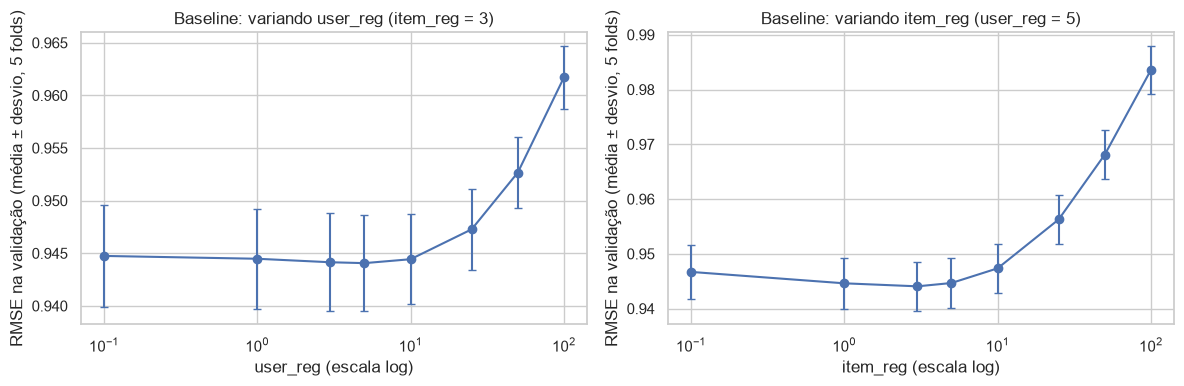

n_epochs= 1: RMSE validação (fold 0) = 0.95442
n_epochs= 2: RMSE validação (fold 0) = 0.93961
n_epochs= 5: RMSE validação (fold 0) = 0.93819
n_epochs=10: RMSE validação (fold 0) = 0.93800
n_epochs=20: RMSE validação (fold 0) = 0.93786
n_epochs=50: RMSE validação (fold 0) = 0.93782


In [15]:
# Pega a combinação com menor RMSE médio na validação
best_baseline = cv_baseline.iloc[0][["user_reg", "item_reg"]].to_dict()
print("Melhor configuração (menor RMSE médio na validação):", best_baseline)

# Curvas de validação variando um lambda de cada vez, com o outro fixo no melhor valor
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (varia, fixo) in zip(axes, [("user_reg", "item_reg"), ("item_reg", "user_reg")]):
    sub = cv_baseline[cv_baseline[fixo] == best_baseline[fixo]].sort_values(varia)
    ax.errorbar(sub[varia], sub["val_rmse_mean"], yerr=sub["val_rmse_std"], marker="o", capsize=3)
    ax.set(xscale="log", xlabel=f"{varia} (escala log)", ylabel="RMSE na validação (média ± desvio, 5 folds)",
           title=f"Baseline: variando {varia} ({fixo} = {best_baseline[fixo]:g})")
fig.tight_layout()
fig.savefig(FIG_DIR / "t11_baseline_cv.png", dpi=150)
plt.show()

# Confere a convergência do ajuste alternado aumentando o número de épocas no fold 0
tr0, va0 = FOLDS[0]
for n_ep in [1, 2, 5, 10, 20, 50]:
    m = BaselineModel(**best_baseline, n_epochs=n_ep)
    m.fit(tr0)
    print(f"n_epochs={n_ep:>2}: RMSE validação (fold 0) = {evaluate_model(m, val=va0)['val_rmse']:.5f}")

In [16]:
# Treina com todo o treino usando os melhores lambdas e avalia no teste uma única vez
baseline_final = BaselineModel(**best_baseline)
final_test_report("Baseline (μ + b_u + b_i)", baseline_final, train_df, test_df)
results_table()

,modelo,RMSE,MAE,NLL,HIT@10,treino (s),inferência (s)
0,Baseline (μ + b_u + b_i),"0.9356 [0.9260, 0.9450]","0.7387 [0.7311, 0.7468]",—,"0.3466 [0.3175, 0.3767]",0.03,0.0


mu (média global do treino) = 3.529

Filmes com MAIOR b_i:
                           title   b_i  n_notas  media_bruta
           Close Shave, A (1995) 1.115       94        4.511
               Casablanca (1942) 1.062      193        4.487
Shawshank Redemption, The (1994) 1.040      220        4.459
         Schindler's List (1993) 1.037      251        4.458
      Wrong Trousers, The (1993) 1.022       96        4.448
          Pather Panchali (1955) 0.985        6        4.500
           Third Man, The (1949) 0.966       52        4.423
              Rear Window (1954) 0.959      169        4.373

Filmes com MENOR b_i:
                                     title    b_i  n_notas  media_bruta
                           Bio-Dome (1996) -1.530       22        1.727
Children of the Corn: The Gathering (1996) -1.522       15        1.267
           Free Willy 3: The Rescue (1997) -1.451       26        1.769
                 Leave It to Beaver (1997) -1.376       37        1.892
         

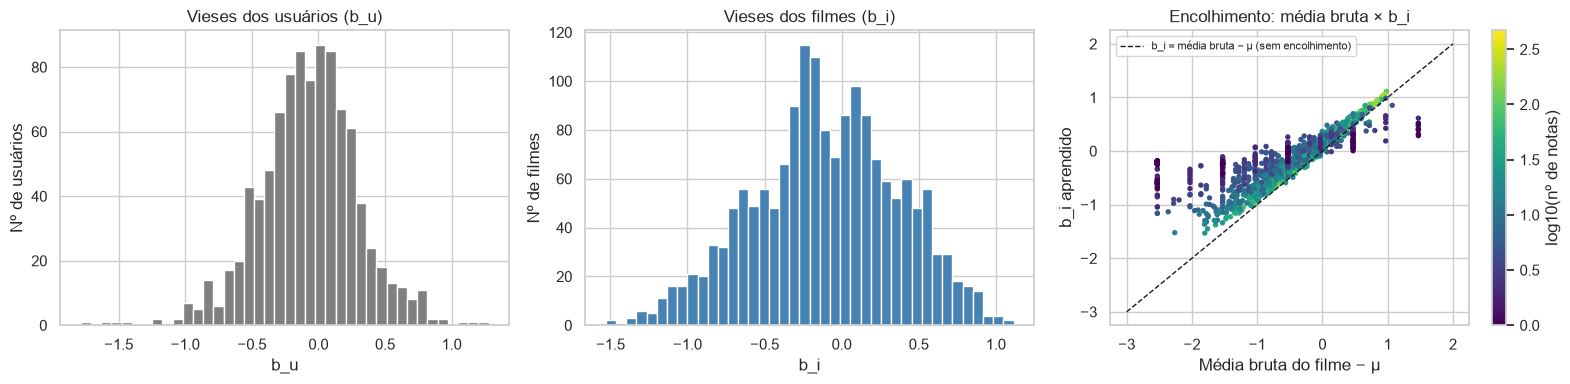

In [17]:
# Junta, para cada filme, o viés aprendido, o número de notas no treino e a média bruta
n_notas_filme_treino = train_df.groupby("item_id").size().reindex(range(len(movies)), fill_value=0)
media_filme_treino = train_df.groupby("item_id")["rating"].mean().reindex(range(len(movies)))

vieses_filmes = movies[["item_id", "title"]].assign(
    b_i=baseline_final.item_bias,
    n_notas=n_notas_filme_treino.values,
    media_bruta=media_filme_treino.values,
)
vieses_filmes["desvio_bruto"] = vieses_filmes["media_bruta"] - baseline_final.global_mean

# Filmes com os maiores e os menores vieses
print(f"mu (média global do treino) = {baseline_final.global_mean:.3f}")
print("\nFilmes com MAIOR b_i:")
print(vieses_filmes.nlargest(8, "b_i")[["title", "b_i", "n_notas", "media_bruta"]].round(3).to_string(index=False))
print("\nFilmes com MENOR b_i:")
print(vieses_filmes.nsmallest(8, "b_i")[["title", "b_i", "n_notas", "media_bruta"]].round(3).to_string(index=False))

# Mede se os filmes mais avaliados também têm viés maior
rho_bi, p_bi = spearmanr(vieses_filmes["n_notas"], vieses_filmes["b_i"])
print(f"\nSpearman (nº de notas no treino × b_i): rho = {rho_bi:.3f}, p = {p_bi:.1e}")

# Distribuição dos vieses e o gráfico de encolhimento, em que a linha tracejada mostra como seria sem regularização
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].hist(baseline_final.user_bias, bins=40, color="gray")
axes[0].set(title="Vieses dos usuários (b_u)", xlabel="b_u", ylabel="Nº de usuários")
axes[1].hist(baseline_final.item_bias, bins=40, color="steelblue")
axes[1].set(title="Vieses dos filmes (b_i)", xlabel="b_i", ylabel="Nº de filmes")
sc = axes[2].scatter(vieses_filmes["desvio_bruto"], vieses_filmes["b_i"], c=np.log10(vieses_filmes["n_notas"]),
                     s=8, cmap="viridis")
axes[2].plot([-3, 2], [-3, 2], "k--", lw=1, label="b_i = média bruta − μ (sem encolhimento)")
axes[2].set(title="Encolhimento: média bruta × b_i", xlabel="Média bruta do filme − μ", ylabel="b_i aprendido")
axes[2].legend(loc="upper left", fontsize=8)
fig.colorbar(sc, ax=axes[2], label="log10(nº de notas)")
fig.tight_layout()
fig.savefig(FIG_DIR / "t11_vieses.png", dpi=150)
plt.show()

**Discussão (Tarefa 1.1)**
- **H1.1a confirmada.** Com λ_u = 5 e λ_i = 3, escolhidos por validação cruzada, a baseline tem RMSE de 0,936 [0,926; 0,945] no teste, bem abaixo do desvio padrão das notas (≈1,13), que é o erro de prever sempre a média. Só os vieses de usuário e de filme já reduzem o erro em cerca de 17%.
- **H1.1b parcialmente confirmada.** Valores grandes de λ pioram bastante o resultado (com λ_i = 100 o RMSE vai a 0,983). Já λ perto de zero quase não piora. Com λ_u = 0,1 o RMSE de validação fica em 0,9447 e com λ_i = 0,1 fica em 0,9467, contra 0,9441 do melhor par, diferenças menores que a variação entre os folds (cerca de 0,005). Provavelmente o sobreajuste nos filmes raros não aparece porque a validação tem poucas notas desses filmes.
- **H1.1c confirmada.** Filmes mais avaliados têm b_i maior (Spearman ρ = 0,30), e o gráfico de encolhimento mostra que filmes com poucas notas ficam com b_i mais perto de zero do que a média bruta deles. Os maiores b_i são de clássicos muito avaliados, como Casablanca e Schindler's List.
- **Vieses dos usuários.** A maioria dos b_u fica entre −0,5 e 0,5, com poucos usuários muito exigentes ou muito generosos.
- **Convergência.** O ajuste estabiliza em cerca de 10 épocas, então as 20 épocas padrão são suficientes.
- **Listas.** O Hit@10 é 0,347. Como o b_u não muda a ordem dos filmes para um mesmo usuário, todos recebem praticamente a mesma lista, ou seja, a baseline não personaliza as recomendações.

---
### Introduzindo vetores latentes

A baseline linear captura diferenças sistemáticas entre usuários e itens, mas não explica por que determinados grupos de usuários atribuem notas semelhantes a determinados grupos de itens.
Para investigar essa estrutura, podemos olhar para a matriz de notas como um todo e perguntar se sua variabilidade pode ser explicada por um número reduzido de dimensões.
Essa perspectiva permite explorar interações globais nos dados e construir uma representação mais compacta das avaliações, codificando usuários e itens em um espaço latente compartilhado.

Uma maneira de investigar essa hipótese é completar a matriz de notas e aplicar Análise de Componentes Principais (PCA, *Principal Component Analysis*).
Para isso, substituímos as notas ausentes pela média do respectivo item, calculada apenas com as avaliações observadas no conjunto de treinamento.
Em seguida, o PCA identifica as principais direções de variação da matriz completada, permitindo representar cada usuário e cada item como vetores em um espaço de baixa dimensionalidade.

Seja $\tilde{R}$ a matriz de notas em que cada nota ausente foi substituída por um valor de imputação, por exemplo, a média do item.
O PCA com $k$ componentes aproxima $\tilde{R}$ por uma matriz de posto $k$:

$$\hat{R}_{ui} = \bar{R}_i + \mathbf{z}_u^\top \mathbf{w}_i$$

onde $\bar{R}_i$ é a média da coluna $i$ de $\tilde{R}$, $\mathbf{z}_u$ e $\mathbf{w}_i$ são as coordenadas do usuário $u$ e do item $i$ nos $k$ primeiros componentes principais.
Sob a perspectiva do PCA, um usuário é codificado como um vetor de pesos que indica a importância de cada componente principal para aquele usuário, que então é decodificado em uma nota para cada item, através da combinação linear com a transformação dos itens no mesmo espaço latente.

> **Tarefa 1.2**
Treine o modelo de PCA com imputação de notas ausentes, utilizando a média de cada item para preencher os valores faltantes. Utilize o protocolo experimental para selecionar o número de componentes principais $k$ e então reporte RMSE e MAE no conjunto de teste para o valor de $k$ selecionado.
>
> Analise e discuta também como o desempenho varia com o número de componentes, discutindo se o aumento da dimensionalidade melhora as previsões, produz ganhos decrescentes ou degrada o desempenho.


In [18]:
class ImputedPCA:
    def __init__(self, n_components: int = 10) -> None:
        self.n_components = n_components
        self.user_embeddings: NDArray[np.float64]
        self.item_embeddings: NDArray[np.float64]
        self.item_means: NDArray[np.float64]
        self.pca = PCA(n_components=n_components)

    def fit(self, train_df: pd.DataFrame) -> None:
        X = ratings_to_matrix(train_df)

        # Imputação de valores ausentes com a média do item
        observed = ~np.isnan(X)
        global_mean = float(X[observed].mean())
        counts = observed.sum(axis=0)
        sums = np.where(observed, X, 0.0).sum(axis=0)

        self.item_means = np.divide(
            sums,
            counts,
            out=np.full(X.shape[1], global_mean),
            where=counts > 0,
        )

        rows, cols = np.where(~observed)
        X[rows, cols] = self.item_means[cols]

        user_scores = self.pca.fit_transform(X)
        self.user_embeddings = user_scores
        self.item_embeddings = self.pca.components_.T

    def predict(
        self,
        user_id: NDArray[np.intp],
        item_id: NDArray[np.intp],
    ) -> NDArray[np.float64]:
        return (
            self.pca.mean_[item_id]
            + np.sum(
                self.user_embeddings[user_id]
                * self.item_embeddings[item_id],
                axis=1,
            )
        )

### Hipóteses da Tarefa 1.2 (escritas antes de rodar)

**H1.2a.** O RMSE vai melhorar com os primeiros componentes, depois parar de melhorar e piorar para $k$ grande (50 a 100), porque os componentes extras passam a ajustar ruído e valores imputados, que não são notas reais.

**H1.2b.** O melhor PCA não vai superar claramente a baseline (RMSE 0,936), porque não tem viés de usuário e cerca de 94% da matriz é preenchida pela média do filme.

O que refutaria as hipóteses seria o RMSE caindo sem parar até $k=100$ (H1.2a) ou o PCA claramente melhor que a baseline, com intervalos de confiança separados (H1.2b).

Melhor k (menor RMSE médio na validação): 10


,n_components,val_rmse_mean,val_rmse_std,val_mae_mean,val_mae_std
8,1,1.0079,0.0042,0.8018,0.0047
7,2,1.0054,0.0041,0.7989,0.0048
5,3,0.9992,0.0046,0.7932,0.0048
3,5,0.9954,0.0043,0.7898,0.0047
0,10,0.9919,0.0041,0.7862,0.0045
1,15,0.9932,0.0042,0.7871,0.0047
2,20,0.9952,0.0043,0.7886,0.0047
4,30,0.9988,0.0052,0.7917,0.0056
6,50,1.0050,0.0042,0.7970,0.0049
9,100,1.0141,0.0038,0.8063,0.0042


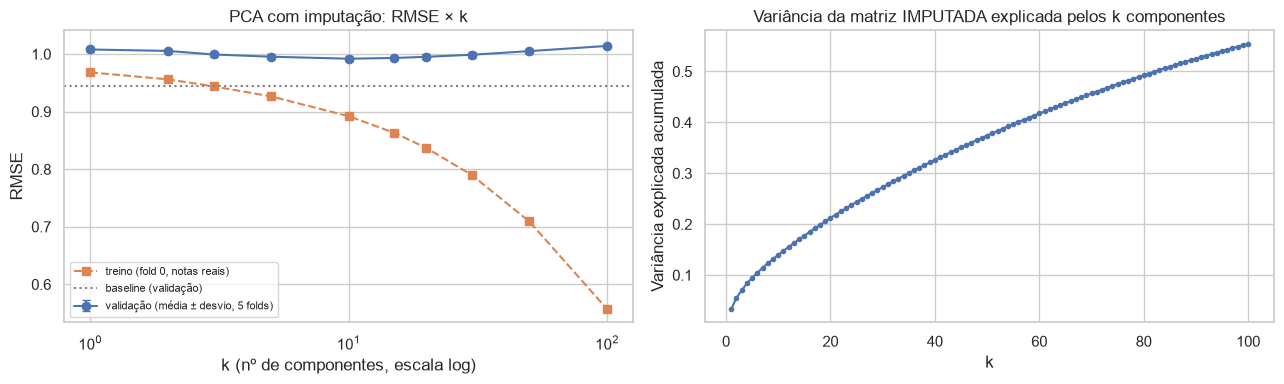

Fração da matriz de treino preenchida por imputação: 94.9%


In [19]:
# Escolhe o número de componentes k por validação cruzada em 5 folds
param_grid_pca = {"n_components": [1, 2, 3, 5, 10, 15, 20, 30, 50, 100]}
cv_pca_folds, cv_pca = cross_validate(ImputedPCA, param_grid_pca)
best_k_pca = int(cv_pca.iloc[0]["n_components"])
print("Melhor k (menor RMSE médio na validação):", best_k_pca)
display(cv_pca.sort_values("n_components").round(4))

# Mede o erro no treino do fold 0 para cada k e guarda a variância explicada pelos componentes
tr0, va0 = FOLDS[0]
treino_rmse = []
for k in param_grid_pca["n_components"]:
    m = ImputedPCA(n_components=k)
    m.fit(tr0)
    treino_rmse.append(evaluate_model(m, treino=tr0)["treino_rmse"])
var_exp = np.cumsum(m.pca.explained_variance_ratio_)   # vem do último ajuste, com k = 100

# RMSE em função de k comparado com a baseline, e a variância explicada acumulada
sub = cv_pca.sort_values("n_components")
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].errorbar(sub["n_components"], sub["val_rmse_mean"], yerr=sub["val_rmse_std"], marker="o", capsize=3,
                 label="validação (média ± desvio, 5 folds)")
axes[0].plot(param_grid_pca["n_components"], treino_rmse, marker="s", ls="--", label="treino (fold 0, notas reais)")
axes[0].axhline(cv_baseline.iloc[0]["val_rmse_mean"], color="gray", ls=":", label="baseline (validação)")
axes[0].set(xscale="log", xlabel="k (nº de componentes, escala log)", ylabel="RMSE",
            title="PCA com imputação: RMSE × k")
axes[0].legend(fontsize=8)
axes[1].plot(np.arange(1, len(var_exp) + 1), var_exp, marker=".")
axes[1].set(xlabel="k", ylabel="Variância explicada acumulada",
            title="Variância da matriz IMPUTADA explicada pelos k componentes")
fig.tight_layout()
fig.savefig(FIG_DIR / "t12_pca_k.png", dpi=150)
plt.show()

# Fração da matriz de treino que foi preenchida com a média do filme
frac_imputada = 1 - len(train_df) / (len(users) * len(movies))
print(f"Fração da matriz de treino preenchida por imputação: {frac_imputada:.1%}")

In [20]:
# Treina com todo o treino usando o melhor k e avalia no teste uma única vez
pca_final = ImputedPCA(n_components=best_k_pca)
final_test_report(f"PCA com imputação (k={best_k_pca})", pca_final, train_df, test_df)
results_table()

,modelo,RMSE,MAE,NLL,HIT@10,treino (s),inferência (s)
0,Baseline (μ + b_u + b_i),"0.9356 [0.9260, 0.9450]","0.7387 [0.7311, 0.7468]",—,"0.3466 [0.3175, 0.3767]",0.03,0.000
1,PCA com imputação (k=10),"0.9735 [0.9633, 0.9832]","0.7697 [0.7615, 0.7781]",—,"0.0205 [0.0118, 0.0291]",0.11,0.003


In [21]:
# Mostra quais filmes cada modelo mais recomenda e quantas notas esses filmes têm no treino
notas_no_treino = train_df.groupby("item_id").size().reindex(range(len(movies)), fill_value=0)
vistos = train_df.groupby("user_id")["item_id"].apply(np.array)

for nome, modelo in [("PCA com imputação", pca_final), ("Baseline", baseline_final)]:
    recomendados = []
    for u in range(len(users)):
        notas = modelo.predict(np.full(len(movies), u), np.arange(len(movies)))
        notas[vistos[u]] = -np.inf
        recomendados.extend(np.argsort(-notas)[:10])
    recomendados = pd.Series(recomendados)
    print(f"{nome}: {(notas_no_treino[recomendados].values <= 5).mean():.1%} dos filmes recomendados têm 5 notas ou menos no treino")
    mais_comuns = recomendados.value_counts().head(5)
    print(pd.DataFrame({"filme": movies.loc[mais_comuns.index, "title"].values,
                        "usuários que recebem": mais_comuns.values,
                        "notas no treino": notas_no_treino[mais_comuns.index].values}).to_string(index=False), "\n")

PCA com imputação: 99.7% dos filmes recomendados têm 5 notas ou menos no treino
                                     filme  usuários que recebem  notas no treino
Marlene Dietrich: Shadow and Light (1996)                    941                1
             Great Day in Harlem, A (1994)                   940                1
                        Prefontaine (1997)                   940                3
                           Star Kid (1997)                   940                2
            They Made Me a Criminal (1939)                   940                1 

Baseline: 0.5% dos filmes recomendados têm 5 notas ou menos no treino
                     filme  usuários que recebem  notas no treino
    Pather Panchali (1955)                   937                6
     Third Man, The (1949)                   891               52
     Close Shave, A (1995)                   849               94
       12 Angry Men (1957)                   848               95
Wrong Trousers, The (1993)

**Discussão (Tarefa 1.2)**
- **H1.2a confirmada.** O RMSE de validação cai de 1,008 (k=1) para 0,992 (k=10) e volta a subir até 1,014 (k=100). No treino o erro continua caindo, de 0,97 para 0,56, então com k grande o modelo se ajusta ao treino e não generaliza.
- **Variância explicada.** Com k=10 os componentes explicam cerca de 14% da variância da matriz imputada, e com k=100 cerca de 55%. A curva não tem um cotovelo claro.
- **H1.2b confirmada.** O PCA com k=10 tem RMSE de 0,974 [0,963; 0,983] no teste, pior que a baseline (0,936), e os intervalos não se sobrepõem.
- **O que a imputação distorce.** O Hit@10 do PCA é só 0,02, contra 0,35 da baseline. Quase todos os filmes que ele recomenda têm 5 notas ou menos no treino, e o mais recomendado tem uma única nota 5. Como a média do filme usada na imputação não tem regularização, um filme com uma nota 5 aparece como um dos melhores do catálogo. Na baseline isso não acontece, porque o λ puxa esses vieses para zero.
- **RMSE e listas.** A diferença de RMSE entre PCA e baseline é pequena, mas a diferença nas listas é enorme. O RMSE é dominado pelos filmes populares do teste e não mostra esse problema.

---

### Fatoração de matrizes (*Matrix Factorization*)

A principal limitação do modelo anterior é que ele depende de notas imputadas, que não correspondem a avaliações reais e podem introduzir vieses no aprendizado dos vetores latentes.
Para superar essa limitação, devemos aprender os vetores latentes diretamente a partir das notas observadas, sem precisar completar previamente a matriz.

A fatoração de matrizes parte da hipótese de que a matriz de notas pode ser aproximada pelo produto de duas matrizes de menor dimensão, ou seja

$$\hat R = Z W^\top,$$
em que $Z\in\mathbb R^{|U|\times k}$ e $W\in\mathbb R^{|I|\times k}$ contêm os vetores latentes dos usuários e dos itens, respectivamente.
Dessa forma, a nota prevista para um par usuário–item é dada pelo produto interno entre suas representações:

$$\hat R_{ui}=\mathbf z_u^\top\mathbf w_i.$$

Entretanto, como vimos na baseline, parte da variação das notas pode ser explicada por diferenças sistemáticas entre usuários e itens, independentemente de suas interações (por exemplo, alguns filmes são mais populares que outros).
Para considerar esses efeitos, incorporamos a média global e os *biases* de usuário e item ao modelo, obtendo a formulação geral com $f(\mathbf{z}_u, \mathbf{w}_i) = \mathbf z_u^\top\mathbf w_i$:

$$\hat R_{ui}=\mu+b_u+b_i+\mathbf z_u^\top\mathbf w_i.$$

Para aprender os parâmetros, minimizamos o erro quadrático entre as notas observadas e as respectivas previsões, considerando apenas os pares usuário–item avaliados no conjunto de treinamento.
Introduzimos também regularização $L_2$, que penaliza valores elevados dos *biases* e das normas dos vetores latentes:

\begin{aligned}
\min_{\mu,b,Z_U,Z_I}\quad
&\sum_{(u,i)\in\Omega}
\left(r_{ui}-\mu-b_u-b_i-\mathbf z_u^\top\mathbf w_i\right)^2\\
&+\lambda_b\left(\sum_u b_u^2+\sum_i b_i^2\right)\\
&+\lambda_z\left(\sum_u\|\mathbf z_u\|_2^2+
\sum_i\|\mathbf w_i\|_2^2\right),
\end{aligned}

em que $\Omega$ é o conjunto de avaliações observadas no treinamento, enquanto $\lambda_b$ e $\lambda_z$ controlam a intensidade da regularização dos *biases* e dos fatores latentes, respectivamente.
Como o problema é não-convexo, sem solução fechada, usamos descida no gradiente para atualizar os parâmetros, iterativamente com base em pequenas amostras do conjunto de treinamento.

> **Tarefa 1.3**
Treine um modelo de fatoração de matrizes utilizando regularização $L_2$.
Selecione o número de dimensões latentes $k$ e os coeficientes de regularização com base no RMSE.
> 
> Reporte RMSE e MAE no conjunto de teste para a configuração selecionada.
Analise como o desempenho varia com $k$ e com a regularização.
Por fim, compare a fatoração com *biases* e sem *biases*, mantendo o mesmo protocolo experimental, para investigar a contribuição dos efeitos aditivos e das interações latentes para a qualidade das previsões.
>
> Siga o mesmo protocolo experimental utilizado para os modelos anteriores.


In [22]:
class MatrixFactorization:
    user_embeddings: NDArray[np.float64]
    item_embeddings: NDArray[np.float64]
    global_mean: float
    user_bias: NDArray[np.float64]
    item_bias: NDArray[np.float64]

    def __init__(
        self,
        n_factors: int = 10,
        n_epochs: int = 20,
        learning_rate: float = 0.01,
        reg: float = 0.1,
        bias_reg: float | None = None,
        use_biases: bool = True,
    ) -> None:
        self.n_factors = n_factors
        self.n_epochs = n_epochs
        self.learning_rate = learning_rate
        self.reg = reg
        self.bias_reg = reg if bias_reg is None else bias_reg
        self.use_biases = use_biases

    def fit(self, train_df: pd.DataFrame) -> None:
        ratings = train_df["rating"].to_numpy(dtype=np.float64)
        users = train_df["user_id"].to_numpy(dtype=np.intp)
        items = train_df["item_id"].to_numpy(dtype=np.intp)

        self.global_mean = float(ratings.mean())
        n_users = int(users.max()) + 1
        n_items = int(items.max()) + 1

        self.user_embeddings = np.random.normal(scale=0.1, size=(n_users, self.n_factors))
        self.item_embeddings = np.random.normal(scale=0.1, size=(n_items, self.n_factors))
        self.user_bias = np.zeros(n_users, dtype=np.float64)
        self.item_bias = np.zeros(n_items, dtype=np.float64)

        for _ in range(self.n_epochs):
            for n in np.random.permutation(len(ratings)):
                u, i, r = users[n], items[n], ratings[n]
                pred = (
                    self.global_mean
                    + self.user_bias[u]
                    + self.item_bias[i]
                    + np.dot(self.user_embeddings[u], self.item_embeddings[i])
                )
                err = r - pred

                # Atualização dos vieses
                if self.use_biases:
                    self.user_bias[u] += self.learning_rate * (err - self.bias_reg * self.user_bias[u])
                    self.item_bias[i] += self.learning_rate * (err - self.bias_reg * self.item_bias[i])

                user_emb_old = self.user_embeddings[u].copy()
                item_emb_old = self.item_embeddings[i].copy()

                self.user_embeddings[u] += self.learning_rate * (err * item_emb_old - self.reg * user_emb_old)
                self.item_embeddings[i] += self.learning_rate * (err * user_emb_old - self.reg * item_emb_old)

    def predict(
        self,
        user_id: NDArray[np.intp],
        item_id: NDArray[np.intp],
    ) -> NDArray[np.float64]:
        return (
            self.global_mean
            + self.user_bias[user_id]
            + self.item_bias[item_id]
            + np.sum(
                self.user_embeddings[user_id] * self.item_embeddings[item_id],
                axis=1,
            )
        )


### Hipóteses da Tarefa 1.3 (escritas antes de rodar)

**H1.3a.** A fatoração com vieses vai ter RMSE menor que a baseline, mas com um ganho modesto, porque a interação vai explicar o gosto pessoal além da qualidade geral avaliada do filme.

**H1.3b.** Com pouca regularização, aumentar $k$ vai piorar a validação (sobreajuste). O melhor $\lambda_z$ vai ser intermediário.

**H1.3c.** Sem vieses, o RMSE vai ser pior do que com vieses, porque os vetores precisam aprender sozinhos os efeitos de usuário e de filme, e a regularização dificulta isso.

**H1.3d.** A fatoração vai ter Hit@10 maior que a baseline, porque personaliza a lista.

O que refutaria as hipóteses seria a fatoração empatar com a baseline (H1.3a), $k$ grande não piorar mesmo com $\lambda_z$ pequeno (H1.3b), a versão sem vieses empatar com a versão com vieses (H1.3c) ou o Hit@10 ficar igual ou menor que o da baseline (H1.3d).

A escolha de hiperparâmetros varia uma coisa de cada vez. Primeiro $\lambda_z$ (`reg`) com $k=10$, depois $k$, depois $\lambda_b$ (`bias_reg`) e, por último, $\lambda_z$ da versão sem vieses. A taxa de aprendizado (0,01) e o número de épocas (20) ficam no padrão do notebook, e a convergência é conferida no fim.

In [23]:
# Passo 1. Varia a regularização dos vetores (λ_z) com k = 10 e λ_b fixo em 0,1
cv_mf_reg_folds, cv_mf_reg = cross_validate(
    MatrixFactorization, {"n_factors": [10], "reg": [0.01, 0.05, 0.1, 0.2], "bias_reg": [0.1]}
)
best_reg = float(cv_mf_reg.iloc[0]["reg"])
print("Melhor λ_z:", best_reg)
cv_mf_reg.round(4)

Melhor λ_z: 0.05


,n_factors,reg,bias_reg,val_rmse_mean,val_rmse_std,val_mae_mean,val_mae_std
0,10,0.05,0.1,0.9350,0.0047,0.7400,0.0039
1,10,0.10,0.1,0.9407,0.0047,0.7453,0.0045
2,10,0.20,0.1,0.9460,0.0043,0.7495,0.0044
3,10,0.01,0.1,0.9552,0.0047,0.7526,0.0034


In [24]:
# Passo 2. Varia k com o melhor λ_z e também com o menor λ_z da grade, para ver o efeito de k com pouca regularização
regs_passo2 = sorted({0.01, best_reg})
cv_mf_k_folds, cv_mf_k = cross_validate(
    MatrixFactorization, {"n_factors": [5, 10, 20, 50], "reg": regs_passo2, "bias_reg": [0.1]}
)
best_k_mf = int(cv_mf_k[cv_mf_k["reg"] == best_reg].iloc[0]["n_factors"])
print("Melhor k (com o melhor λ_z):", best_k_mf)
cv_mf_k.sort_values(["reg", "n_factors"]).round(4)

Melhor k (com o melhor λ_z): 10


,n_factors,reg,bias_reg,val_rmse_mean,val_rmse_std,val_mae_mean,val_mae_std
4,5,0.01,0.1,0.9498,0.0060,0.7486,0.0062
5,10,0.01,0.1,0.9552,0.0047,0.7526,0.0034
6,20,0.01,0.1,0.9719,0.0043,0.7631,0.0046
7,50,0.01,0.1,0.9884,0.0040,0.7773,0.0039
3,5,0.05,0.1,0.9384,0.0052,0.7425,0.0053
0,10,0.05,0.1,0.9350,0.0047,0.7400,0.0039
1,20,0.05,0.1,0.9358,0.0047,0.7393,0.0043
2,50,0.05,0.1,0.9367,0.0037,0.7397,0.0044


In [25]:
# Passo 3. Varia a regularização dos vieses (λ_b) com o melhor k e o melhor λ_z
cv_mf_breg_folds, cv_mf_breg = cross_validate(
    MatrixFactorization, {"n_factors": [best_k_mf], "reg": [best_reg], "bias_reg": [0.01, 0.05, 0.1, 0.2]}
)
best_bias_reg = float(cv_mf_breg.iloc[0]["bias_reg"])
print("Melhor λ_b:", best_bias_reg)
cv_mf_breg.round(4)

Melhor λ_b: 0.05


,n_factors,reg,bias_reg,val_rmse_mean,val_rmse_std,val_mae_mean,val_mae_std
0,10,0.05,0.05,0.9344,0.0049,0.7379,0.0040
1,10,0.05,0.01,0.9345,0.0051,0.7365,0.0040
2,10,0.05,0.10,0.9350,0.0047,0.7400,0.0039
3,10,0.05,0.20,0.9375,0.0044,0.7446,0.0039


In [26]:
# Passo 4. Versão sem vieses (só μ + z·w), com o mesmo k e escolhendo o λ_z dela
cv_mf_sem_folds, cv_mf_sem = cross_validate(
    MatrixFactorization, {"n_factors": [best_k_mf], "reg": [0.01, 0.05, 0.1, 0.2], "use_biases": [False]}
)
best_reg_sem = float(cv_mf_sem.iloc[0]["reg"])
print("Melhor λ_z sem vieses:", best_reg_sem)
cv_mf_sem.round(4)

Melhor λ_z sem vieses: 0.05


,n_factors,reg,use_biases,val_rmse_mean,val_rmse_std,val_mae_mean,val_mae_std
0,10,0.05,False,0.9556,0.0047,0.7563,0.0050
1,10,0.10,False,0.9667,0.0051,0.7718,0.0057
2,10,0.01,False,0.9711,0.0040,0.7625,0.0043
3,10,0.20,False,1.0257,0.0047,0.8376,0.0046


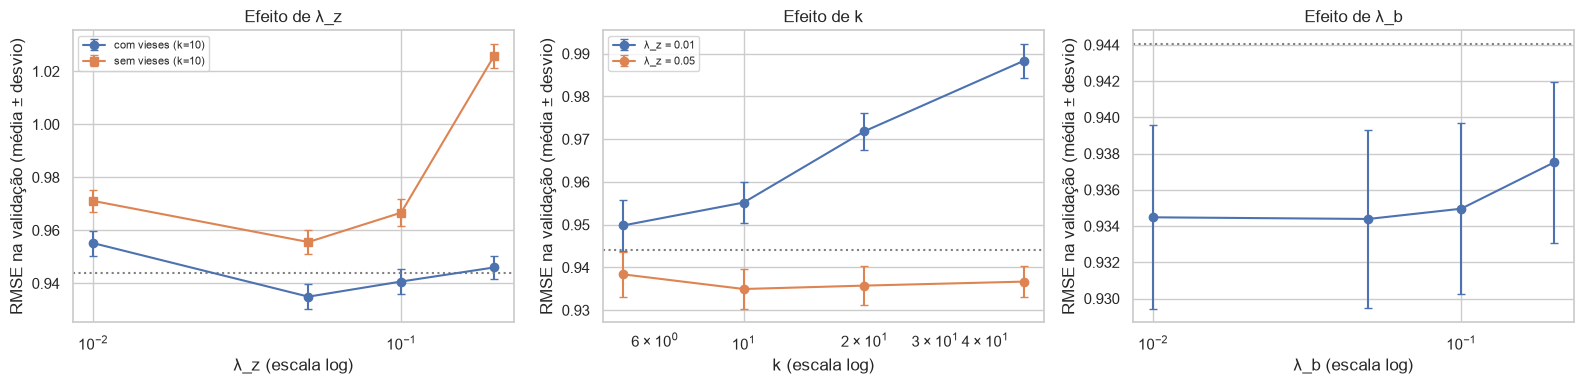

n_epochs= 5: RMSE validação (fold 0) = 0.9458
n_epochs=10: RMSE validação (fold 0) = 0.9398
n_epochs=20: RMSE validação (fold 0) = 0.9276
n_epochs=40: RMSE validação (fold 0) = 0.9415


In [27]:
# Gráficos da validação cruzada, um hiperparâmetro de cada vez
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

sub = cv_mf_reg.sort_values("reg")
axes[0].errorbar(sub["reg"], sub["val_rmse_mean"], yerr=sub["val_rmse_std"], marker="o", capsize=3, label="com vieses (k=10)")
sub = cv_mf_sem.sort_values("reg")
axes[0].errorbar(sub["reg"], sub["val_rmse_mean"], yerr=sub["val_rmse_std"], marker="s", capsize=3, label=f"sem vieses (k={best_k_mf})")
axes[0].set(xscale="log", xlabel="λ_z (escala log)", ylabel="RMSE na validação (média ± desvio)", title="Efeito de λ_z")
axes[0].legend(fontsize=8)

for reg in regs_passo2:
    sub = cv_mf_k[cv_mf_k["reg"] == reg].sort_values("n_factors")
    axes[1].errorbar(sub["n_factors"], sub["val_rmse_mean"], yerr=sub["val_rmse_std"], marker="o", capsize=3, label=f"λ_z = {reg:g}")
axes[1].set(xscale="log", xlabel="k (escala log)", ylabel="RMSE na validação (média ± desvio)", title="Efeito de k")
axes[1].legend(fontsize=8)

sub = cv_mf_breg.sort_values("bias_reg")
axes[2].errorbar(sub["bias_reg"], sub["val_rmse_mean"], yerr=sub["val_rmse_std"], marker="o", capsize=3)
axes[2].set(xscale="log", xlabel="λ_b (escala log)", ylabel="RMSE na validação (média ± desvio)", title="Efeito de λ_b")

for ax in axes:
    ax.axhline(cv_baseline.iloc[0]["val_rmse_mean"], color="gray", ls=":", label="baseline")
fig.tight_layout()
fig.savefig(FIG_DIR / "t13_fatoracao_cv.png", dpi=150)
plt.show()

# Confere a convergência do SGD aumentando o número de épocas no fold 0, com a melhor configuração
tr0, va0 = FOLDS[0]
for n_ep in [5, 10, 20, 40]:
    set_seed(SEED)
    m = MatrixFactorization(n_factors=best_k_mf, reg=best_reg, bias_reg=best_bias_reg, n_epochs=n_ep)
    m.fit(tr0)
    print(f"n_epochs={n_ep:>2}: RMSE validação (fold 0) = {evaluate_model(m, val=va0)['val_rmse']:.4f}")

In [28]:
# Treina as duas versões com todo o treino e avalia no teste uma única vez
mf_final = MatrixFactorization(n_factors=best_k_mf, reg=best_reg, bias_reg=best_bias_reg)
final_test_report(f"Fatoração com vieses (k={best_k_mf})", mf_final, train_df, test_df)

mf_sem_vieses_final = MatrixFactorization(n_factors=best_k_mf, reg=best_reg_sem, use_biases=False)
final_test_report(f"Fatoração sem vieses (k={best_k_mf})", mf_sem_vieses_final, train_df, test_df)
results_table()

,modelo,RMSE,MAE,NLL,HIT@10,treino (s),inferência (s)
0,Baseline (μ + b_u + b_i),"0.9356 [0.9260, 0.9450]","0.7387 [0.7311, 0.7468]",—,"0.3466 [0.3175, 0.3767]",0.03,0.000
1,PCA com imputação (k=10),"0.9735 [0.9633, 0.9832]","0.7697 [0.7615, 0.7781]",—,"0.0205 [0.0118, 0.0291]",0.11,0.003
2,Fatoração com vieses (k=10),"0.9169 [0.9071, 0.9263]","0.7216 [0.7136, 0.7293]",—,"0.3746 [0.3445, 0.4026]",56.65,0.006
3,Fatoração sem vieses (k=10),"0.9280 [0.9180, 0.9377]","0.7304 [0.7226, 0.7386]",—,"0.4467 [0.4155, 0.4779]",52.49,0.004


In [29]:
# Mede se as listas são personalizadas, contando quantos filmes diferentes aparecem nos top-10 de todos os usuários
for nome, modelo in [("Baseline", baseline_final), ("PCA com imputação", pca_final),
                     ("Fatoração com vieses", mf_final), ("Fatoração sem vieses", mf_sem_vieses_final)]:
    recomendados = []
    for u in range(len(users)):
        notas = modelo.predict(np.full(len(movies), u), np.arange(len(movies)))
        notas[vistos[u]] = -np.inf
        recomendados.extend(np.argsort(-notas)[:10])
    recomendados = np.array(recomendados)
    print(f"{nome}: {len(np.unique(recomendados))} filmes diferentes nas listas, "
          f"{(notas_no_treino.values[recomendados] <= 5).mean():.1%} deles com 5 notas ou menos no treino")

Baseline: 30 filmes diferentes nas listas, 0.5% deles com 5 notas ou menos no treino
PCA com imputação: 28 filmes diferentes nas listas, 99.7% deles com 5 notas ou menos no treino
Fatoração com vieses: 164 filmes diferentes nas listas, 0.4% deles com 5 notas ou menos no treino
Fatoração sem vieses: 485 filmes diferentes nas listas, 1.3% deles com 5 notas ou menos no treino


**Discussão (Tarefa 1.3)**
- **H1.3a confirmada.** A fatoração com vieses (k=10, λ_z=0,05 e λ_b=0,05) tem RMSE de 0,917 [0,907; 0,926] no teste, contra 0,936 [0,926; 0,945] da baseline. O ganho é de cerca de 2%, pequeno como previsto, e os intervalos praticamente se encostam. Na validação cruzada a diferença foi parecida (0,934 contra 0,944).
- **H1.3b confirmada.** Com λ_z = 0,01, o RMSE de validação piora de 0,950 para 0,988 quando k vai de 5 para 50. Com λ_z = 0,05, o valor de k quase não importa (entre 0,935 e 0,938). O melhor λ_z foi o intermediário, já que 0,01 sobreajusta e 0,1 ou 0,2 regularizam demais.
- **Regularização dos vieses.** Valores de λ_b entre 0,01 e 0,1 dão praticamente o mesmo resultado, e só 0,2 piora um pouco.
- **H1.3c parcialmente confirmada.** Sem vieses o RMSE piora, mas a diferença no teste é pequena (0,928 contra 0,917) e os intervalos se sobrepõem. Na validação a diferença foi maior (0,956 contra 0,934).
- **H1.3d confirmada, com ressalva.** O Hit@10 da fatoração com vieses (0,375) é maior que o da baseline (0,347), mas os intervalos se sobrepõem. Já a versão sem vieses, que tem RMSE pior, tem o melhor Hit@10 de todos (0,447). Ela também é a mais personalizada, com 485 filmes diferentes nas listas, contra 164 da versão com vieses e 30 da baseline. Uma explicação provável é que, com vieses, o b_i dos filmes bem avaliados domina a ordenação e as listas ficam parecidas com as da baseline.
- **Menor RMSE e melhores listas.** O modelo com menor RMSE não é o que gera as melhores listas. O RMSE mede o erro nas notas do teste, que são dominadas por filmes populares, enquanto a lista depende de ordenar todos os filmes que o usuário ainda não viu, então as duas métricas avaliam coisas diferentes.
- **Convergência e tempo.** No fold 0, o RMSE melhora até 20 épocas e piora com 40, o que indica que treinar o SGD por mais tempo também leva a sobreajuste. O número de épocas ficou no padrão do notebook e não foi escolhido por validação cruzada, o que é uma limitação. O treino final da fatoração levou cerca de 55 s, contra menos de 1 s da baseline e do PCA.

---
## Etapa 2: Suposições sobre a estrutura latente

Na etapa anterior, investigamos modelos que estimam notas a partir de vieses aditivos e representações latentes de usuários e itens.
A fatoração de matrizes procura representações que aproximem as avaliações observadas, mas não define, por si só, uma distribuição probabilística completa para os dados.

Nesta etapa, exploraremos uma abordagem probabilística baseada no PCA Probabilístico (*Probabilistic Principal Component Analysis*, PPCA), adaptada ao problema de recomendação.
Essa formulação descreve as avaliações por meio de variáveis latentes e ruído gaussiano, permitindo explicitar a variância do ruído, estimar a verossimilhança dos dados e investigar como as suposições probabilísticas afetam as previsões.

Ao contrário das implementações clássicas de PPCA e VAE, em que o encoder é treinado para mapear as observações para a distribuição posterior, aqui, como os usuários do conjunto de dados são conhecidos durante o treinamento, podemos estimar um embedding para cada um deles e armazenar essas representações após o ajuste do modelo.
Isso é equivalente a um *encoder* que mapeia cada usuário para uma distribuição posterior com o máximo de liberdade, sem lidar com features de usuário, vieses indutivos ou generalização para novos usuários.


### PCA Probabilístico

O PCA clássico identifica um subespaço linear de dimensão reduzida que representa a estrutura de variância dos dados. O PPCA estende essa ideia ao assumir que as observações são geradas por transformações lineares de variáveis latentes gaussianas, acrescidas de ruído gaussiano.

No problema de recomendação, podemos representar a matriz de avaliações por $R\in\mathbb R^{n\times m}$, em que $n$ é o número de usuários e $m$ é o número de filmes. Cada usuário corresponde a uma observação, e cada filme corresponde a uma dimensão observada. Como os usuários do conjunto de dados são conhecidos durante o treinamento, podemos estimar um embedding para cada um deles e armazenar essas representações após o ajuste do modelo.

Seja $\mathbf z_u\in\mathbb R^k$ a variável latente do usuário $u$, e seja $\mathbf w_i\in\mathbb R^k$ o vetor de cargas associado ao filme $i$. O modelo assume que

$$
\mathbf z_u\sim\mathcal N(\mathbf 0,I_k)
$$

e que a avaliação do usuário $u$ para o filme $i$ segue

$$
R_{ui}\mid\mathbf z_u
\sim
\mathcal N\left(
\mu_i+\mathbf z_u^\top\mathbf w_i,
\sigma^2
\right),
$$

em que $\mu_i$ é a média associada ao filme $i$, $k$ é a dimensão latente e $\sigma^2$ é a variância do ruído, considerada fixa durante o treinamento.
A média condicional da avaliação é, portanto,

$$
\mathbb E[R_{ui}\mid\mathbf z_u]
=
\mu_i+\mathbf z_u^\top\mathbf w_i.
$$

Essa formulação representa as avaliações por meio de uma estrutura linear de baixa dimensão, sem introduzir vieses aditivos específicos de usuários.
A diferença fundamental em relação à fatoração de matrizes determinística está na distribuição probabilística atribuída às avaliações e às variáveis latentes.

O treinamento pode ser realizado pelo algoritmo EM (*Expectation-Maximization*).
Seja $\Omega_u$ o conjunto de filmes avaliados pelo usuário $u$ e $\Omega_i$ o conjunto de usuários que avaliaram o filme $i$.
Na etapa E, como o modelo é linear e gaussiano, a posterior de cada usuário, condicionada às avaliações observadas e aos parâmetros atuais, é gaussiana, $p(\mathbf z_u\mid R_u)=\mathcal N(\mathbf m_u, S_u)$, com

$$
S_u=\left( I_k + \frac{1}{\sigma^2} \sum_{i\in\Omega_u} \mathbf w_i\mathbf w_i^\top\right)^{-1},
\qquad
\mathbf m_u=\frac{1}{\sigma^2} \, S_u\sum_{i\in\Omega_u}\mathbf w_i\,(r_{ui}-\mu_i).
$$

Na etapa M, atualizamos as médias dos filmes e os vetores de cargas para maximizar a verossimilhança esperada.
Definindo $\boldsymbol\theta_i=(\mu_i,\mathbf w_i)$ e $\boldsymbol\phi_u=(1,\mathbf z_u)$, cada filme resolve um sistema de mínimos quadrados em que as posteriores entram pelos momentos $\mathbb E[\boldsymbol\phi_u]=(1,\mathbf m_u)$ e $\mathbb E[\mathbf z_u\mathbf z_u^\top]=S_u+\mathbf m_u\mathbf m_u^\top$:

$$
\boldsymbol\theta_i=\left(\sum_{u\in\Omega_i}\mathbb E[\boldsymbol\phi_u\boldsymbol\phi_u^\top]\right)^{-1}\sum_{u\in\Omega_i}r_{ui}\,\mathbb E[\boldsymbol\phi_u].
$$

Como a matriz de avaliações é esparsa, cada usuário contribui para a estimação apenas por meio dos filmes que avaliou. As avaliações ausentes são tratadas como dados não observados, e não como notas iguais a zero. Após o treinamento, as médias dos embeddings posteriores podem ser armazenadas como representações dos usuários, permitindo realizar previsões diretamente para os pares usuário–filme.

Para uma avaliação observada $r_{ui}$, a densidade condicional é

$$
p(r_{ui}\mid\mathbf z_u)
=
\frac{1}{\sqrt{2\pi\sigma^2}}
\exp\left(
-\frac{
(r_{ui}-\mu_i-\mathbf w_i^\top\mathbf z_u)^2
}{2\sigma^2}
\right).
$$

A log-verossimilhança conjunta das avaliações observadas, condicionada às variáveis latentes, é obtida somando as contribuições dos pares usuário–filme observados. O prior gaussiano das variáveis latentes também participa do modelo probabilístico, favorecendo representações compatíveis com a distribuição $\mathcal N(\mathbf 0,I_k)$.

Para prever a avaliação de um par usuário–filme, utilizamos a média condicional calculada com o embedding posterior estimado:

$$
\hat R_{ui}
=
\mu_i+\mathbf w_i^\top\mathbb E[\mathbf z_u\mid R_u],
$$

em que $R_u$ representa as avaliações observadas do usuário $u$. Essa previsão corresponde à média da distribuição preditiva quando os parâmetros do modelo são considerados fixos e a incerteza sobre a variável latente é integrada.

A variância $\sigma^2$ controla o ruído residual assumido pelo modelo. Valores menores atribuem maior concentração às avaliações em torno da média condicional; valores maiores representam maior dispersão. Como a variância é fixada durante o treinamento nesta implementação, ela deve ser selecionada como hiperparâmetro.

> **Tarefa 2.1**
Treine o modelo PPCA para a matriz esparsa de avaliações e selecione o número de dimensões latentes $k$ e a variância do ruído $\sigma^2$ usando o protocolo experimental.
Compare o RMSE com os modelos da etapa anterior e investigue se a configuração que minimiza o RMSE também produz a melhor log-verossimilhança negativa média (*Negative Log-Likelihood*, NLL).
>
> Discuta como a variância do ruído afeta a distribuição das avaliações, como o prior gaussiano influencia as representações latentes e quais são as implicações de estimar embeddings específicos para os usuários conhecidos durante o treinamento.

In [30]:
class PPCA:
    user_embeddings: NDArray[np.float64]
    item_embeddings: NDArray[np.float64]
    item_means: NDArray[np.float64]
    user_covariances: NDArray[np.float64]

    def __init__(
        self, n_factors: int = 10, n_epochs: int = 100, sigma2: float = 1.0
    ) -> None:
        self.n_factors = n_factors
        self.n_epochs = n_epochs
        self.sigma2 = sigma2

    def fit(self, train_df: pd.DataFrame) -> None:
        X = ratings_to_matrix(train_df)
        observed = ~np.isnan(X)
        values = np.where(observed, X, 0.0)
        weights = observed.astype(np.float64)

        counts = observed.sum(axis=0)
        global_mean = values.sum() / observed.sum()
        self.item_means = np.divide(
            values.sum(axis=0),
            counts,
            out=np.full(X.shape[1], global_mean),
            where=counts > 0,
        )

        n_users, n_items = X.shape
        k = self.n_factors
        sigma2 = self.sigma2
        eye = np.eye(k)

        self.item_embeddings = np.random.normal(
            scale=0.1, size=(n_items, k)
        )

        item_outer = (
            self.item_embeddings[:, :, None]
            * self.item_embeddings[:, None, :]
        )

        for _ in range(self.n_epochs):
            centered = np.where(observed, X - self.item_means, 0.0)

            precision = eye + np.einsum("ui,ijk->ujk", weights, item_outer) / sigma2

            self.user_covariances = np.linalg.inv(precision)

            rhs = centered @ self.item_embeddings / sigma2
            self.user_embeddings = (
                self.user_covariances @ rhs[:, :, None]
            )[:, :, 0]

            user_means = np.column_stack(
                (np.ones(n_users), self.user_embeddings)
            )

            user_second = np.zeros((n_users, k + 1, k + 1))
            user_second[:, 0, 0] = 1.0
            user_second[:, 0, 1:] = self.user_embeddings
            user_second[:, 1:, 0] = self.user_embeddings
            user_second[:, 1:, 1:] = (
                self.user_covariances
                + self.user_embeddings[:, :, None]
                * self.user_embeddings[:, None, :]
            )

            A = np.einsum("ui,uab->iab", weights, user_second)

            b = values.T @ user_means
            theta = np.linalg.solve(A, b[:, :, None])[:, :, 0]

            self.item_means = theta[:, 0]
            self.item_embeddings = theta[:, 1:]

            item_outer = (
                self.item_embeddings[:, :, None]
                * self.item_embeddings[:, None, :]
            )

        centered = np.where(observed, X - self.item_means, 0.0)

        precision = eye + np.einsum("ui,ijk->ujk", weights, item_outer) / sigma2

        self.user_covariances = np.linalg.inv(precision)

        rhs = centered @ self.item_embeddings / sigma2
        self.user_embeddings = (
            self.user_covariances @ rhs[:, :, None]
        )[:, :, 0]

    def predict(
        self,
        user_id: NDArray[np.intp],
        item_id: NDArray[np.intp],
    ) -> NDArray[np.float64]:
        return self.item_means[item_id] + np.sum(
            self.user_embeddings[user_id] * self.item_embeddings[item_id],
            axis=1,
        )

    def predict_log_proba(
        self,
        user_id: NDArray[np.intp],
        item_id: NDArray[np.intp],
        ratings: NDArray[np.float64],
    ) -> NDArray[np.float64]:
        user_embeddings = self.user_embeddings[user_id]
        item_embeddings = self.item_embeddings[item_id]
        covariances = self.user_covariances[user_id]

        means = self.item_means[item_id] + np.sum(
            user_embeddings * item_embeddings, axis=1
        )

        variances = self.sigma2 + np.einsum(
            "ni,nij,nj->n",
            item_embeddings,
            covariances,
            item_embeddings,
        )

        return -0.5 * (
            np.log(2 * np.pi * variances)
            + (ratings - means) ** 2 / variances
        )

### Hipóteses da Tarefa 2.1 (escritas antes de rodar)

**H2.1a.** O PPCA vai ter RMSE pior que a fatoração com vieses, porque não tem viés de usuário e a média de cada filme ($\mu_i$) não tem regularização.

**H2.1b.** O $\sigma^2$ que dá o melhor RMSE não vai ser o mesmo que dá a melhor NLL. Para o RMSE, o $\sigma^2$ funciona como regularização, e para a NLL ele também precisa representar o tamanho real do erro.

**H2.1c.** As listas do PPCA vão ter o mesmo problema do PCA, recomendando filmes com pouquíssimas notas, porque $\mu_i$ também não tem prior.

O que refutaria as hipóteses seria o PPCA empatar ou ganhar da fatoração com vieses (H2.1a), o mesmo $\sigma^2$ ser o melhor nas duas métricas (H2.1b) ou as listas do PPCA terem poucos filmes raros (H2.1c).

A escolha de hiperparâmetros varia uma coisa de cada vez. Primeiro $\sigma^2$ com $k=10$, depois $k$ com o melhor $\sigma^2$. Usamos 30 épocas do EM em vez das 100 do padrão, porque o EM converge bem antes disso (conferido no fim).

In [36]:
# Passo 1. Varia a variância do ruído σ² com k = 10
cv_ppca_s2_folds, cv_ppca_s2 = cross_validate(
    PPCA, {"n_factors": [10], "sigma2": [0.5, 0.75, 1.0, 1.5, 2.0], "n_epochs": [30]}
)
best_sigma2 = float(cv_ppca_s2.iloc[0]["sigma2"])
best_sigma2_nll = float(cv_ppca_s2.sort_values("val_nll_mean").iloc[0]["sigma2"])
print("σ² com melhor RMSE:", best_sigma2, "| σ² com melhor NLL:", best_sigma2_nll)
cv_ppca_s2.sort_values("sigma2").round(4)

σ² com melhor RMSE: 2.0 | σ² com melhor NLL: 1.0


,n_factors,sigma2,n_epochs,val_rmse_mean,val_rmse_std,val_mae_mean,val_mae_std,val_nll_mean,val_nll_std
4,10,0.50,30,1.0535,0.0045,0.8069,0.0030,1.6645,0.0106
3,10,0.75,30,1.0171,0.0036,0.7828,0.0022,1.4666,0.0069
2,10,1.00,30,0.9942,0.0034,0.7677,0.0023,1.4233,0.0047
1,10,1.50,30,0.9658,0.0051,0.7497,0.0037,1.4477,0.0034
0,10,2.00,30,0.9515,0.0043,0.7419,0.0043,1.5066,0.0021


In [37]:
# Passo 2. Varia k com o σ² de melhor RMSE
cv_ppca_k_folds, cv_ppca_k = cross_validate(
    PPCA, {"n_factors": [2, 5, 10, 20, 40], "sigma2": [best_sigma2], "n_epochs": [30]}
)
best_k_ppca = int(cv_ppca_k.iloc[0]["n_factors"])
print("Melhor k:", best_k_ppca)
cv_ppca_k.sort_values("n_factors").round(4)

Melhor k: 40


,n_factors,sigma2,n_epochs,val_rmse_mean,val_rmse_std,val_mae_mean,val_mae_std,val_nll_mean,val_nll_std
2,2,2.0,30,0.9495,0.0046,0.7435,0.0050,1.4991,0.0025
4,5,2.0,30,0.9549,0.0038,0.7441,0.0045,1.5052,0.0016
3,10,2.0,30,0.9515,0.0043,0.7419,0.0043,1.5066,0.0021
1,20,2.0,30,0.9448,0.0044,0.7386,0.0051,1.5069,0.0020
0,40,2.0,30,0.9405,0.0046,0.7359,0.0052,1.5063,0.0020


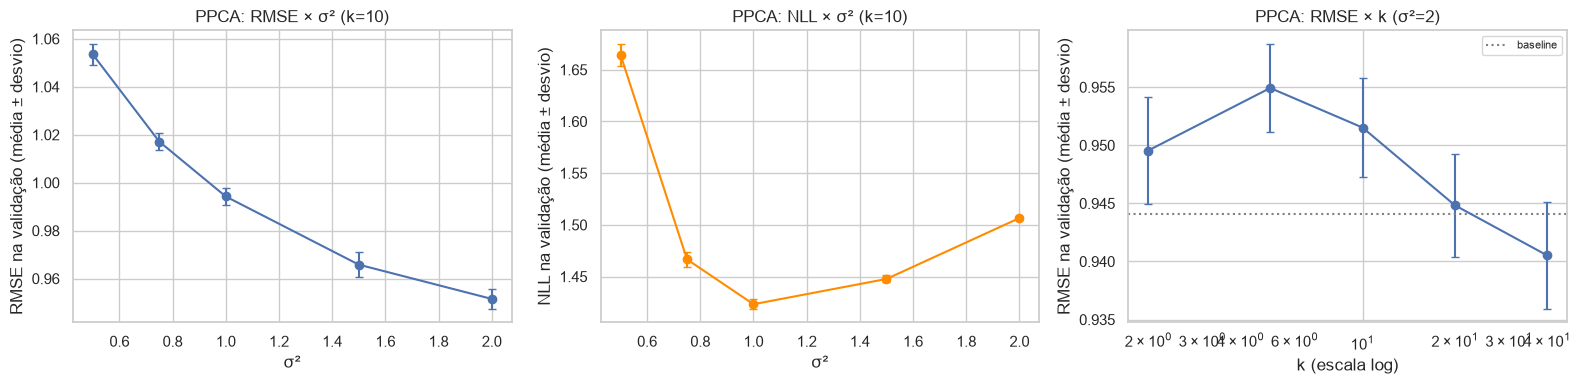

n_epochs= 5: RMSE = 0.9395, NLL = 1.5046 (validação, fold 0)
n_epochs=10: RMSE = 0.9369, NLL = 1.5045 (validação, fold 0)
n_epochs=30: RMSE = 0.9367, NLL = 1.5048 (validação, fold 0)
n_epochs=60: RMSE = 0.9367, NLL = 1.5048 (validação, fold 0)


In [38]:
# RMSE e NLL em função de σ² e de k, lado a lado
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sub = cv_ppca_s2.sort_values("sigma2")
axes[0].errorbar(sub["sigma2"], sub["val_rmse_mean"], yerr=sub["val_rmse_std"], marker="o", capsize=3)
axes[0].set(xlabel="σ²", ylabel="RMSE na validação (média ± desvio)", title="PPCA: RMSE × σ² (k=10)")
axes[1].errorbar(sub["sigma2"], sub["val_nll_mean"], yerr=sub["val_nll_std"], marker="o", capsize=3, color="darkorange")
axes[1].set(xlabel="σ²", ylabel="NLL na validação (média ± desvio)", title="PPCA: NLL × σ² (k=10)")
sub = cv_ppca_k.sort_values("n_factors")
axes[2].errorbar(sub["n_factors"], sub["val_rmse_mean"], yerr=sub["val_rmse_std"], marker="o", capsize=3)
axes[2].axhline(cv_baseline.iloc[0]["val_rmse_mean"], color="gray", ls=":", label="baseline")
axes[2].set(xscale="log", xlabel="k (escala log)", ylabel="RMSE na validação (média ± desvio)",
            title=f"PPCA: RMSE × k (σ²={best_sigma2:g})")
axes[2].legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIG_DIR / "t21_ppca_cv.png", dpi=150)
plt.show()

# Confere a convergência do EM aumentando o número de épocas no fold 0
tr0, va0 = FOLDS[0]
for n_ep in [5, 10, 30, 60]:
    m = PPCA(n_factors=best_k_ppca, sigma2=best_sigma2, n_epochs=n_ep)
    set_seed(SEED)
    m.fit(tr0)
    r = evaluate_model(m, val=va0)
    print(f"n_epochs={n_ep:>2}: RMSE = {r['val_rmse']:.4f}, NLL = {r['val_nll']:.4f} (validação, fold 0)")

In [39]:
# Treina com todo o treino usando o melhor k e o σ² de melhor RMSE, e avalia no teste uma única vez
ppca_final = PPCA(n_factors=best_k_ppca, sigma2=best_sigma2, n_epochs=30)
final_test_report(f"PPCA (k={best_k_ppca}, σ²={best_sigma2:g})", ppca_final, train_df, test_df)
results_table()

,modelo,RMSE,MAE,NLL,HIT@10,treino (s),inferência (s)
0,Baseline (μ + b_u + b_i),"0.9356 [0.9260, 0.9450]","0.7387 [0.7311, 0.7468]",—,"0.3466 [0.3175, 0.3767]",0.03,0.000
1,PCA com imputação (k=10),"0.9735 [0.9633, 0.9832]","0.7697 [0.7615, 0.7781]",—,"0.0205 [0.0118, 0.0291]",0.11,0.003
2,Fatoração com vieses (k=10),"0.9169 [0.9071, 0.9263]","0.7216 [0.7136, 0.7293]",—,"0.3746 [0.3445, 0.4026]",56.65,0.006
3,Fatoração sem vieses (k=10),"0.9280 [0.9180, 0.9377]","0.7304 [0.7226, 0.7386]",—,"0.4467 [0.4155, 0.4779]",52.49,0.004
4,"PPCA (k=40, σ²=2)","0.9134 [0.9038, 0.9234]","0.7150 [0.7076, 0.7231]","1.4932 [1.4892, 1.4976]","0.0151 [0.0075, 0.0237]",122.19,0.008


In [40]:
# Mesma contagem da Tarefa 1.3, para ver se as listas do PPCA também puxam filmes com poucas notas
recomendados = []
for u in range(len(users)):
    notas = ppca_final.predict(np.full(len(movies), u), np.arange(len(movies)))
    notas[vistos[u]] = -np.inf
    recomendados.extend(np.argsort(-notas)[:10])
recomendados = np.array(recomendados)
print(f"PPCA: {len(np.unique(recomendados))} filmes diferentes nas listas, "
      f"{(notas_no_treino.values[recomendados] <= 5).mean():.1%} deles com 5 notas ou menos no treino")

PPCA: 157 filmes diferentes nas listas, 94.0% deles com 5 notas ou menos no treino


**Discussão (Tarefa 2.1)**
- **H2.1a refutada.** O PPCA com k=40 e σ²=2 tem RMSE de 0,913 [0,904; 0,923] no teste, praticamente igual ao da fatoração com vieses (0,917 [0,907; 0,926]), com intervalos que se sobrepõem. Mesmo sem viés de usuário, o prior gaussiano parece compensar, já que ele puxa o vetor de cada usuário para zero quando há poucas notas.
- **H2.1b confirmada.** O σ² com melhor RMSE foi 2,0, enquanto o com melhor NLL foi 1,0. Com σ²=2 a NLL de validação piora de 1,42 para 1,51. Para acertar a nota média, o modelo se beneficia de bastante regularização, mas para dar boas probabilidades o σ² precisa ficar perto do tamanho real do erro.
- **Papel de σ² e do prior.** Como o prior é N(0, I), o σ² funciona como a força da regularização. Quanto maior o σ², menos o modelo confia nas notas de cada usuário e mais o vetor dele fica perto de zero. Isso ajuda a explicar por que, com σ²=2, aumentar k de 2 para 40 não gerou sobreajuste, diferente da fatoração com λ_z pequeno.
- **H2.1c confirmada.** As listas do PPCA repetem o problema do PCA. Dos filmes recomendados, 94% têm 5 notas ou menos no treino, e o Hit@10 é só 0,015. A média de cada filme (μ_i) é estimada sem prior, então filmes com uma ou duas notas altas ficam no topo. Mais uma vez, o menor RMSE não veio junto com a melhor lista.
- **Limitação.** O melhor σ² e o melhor k ficaram no limite da grade testada, e o RMSE de validação ainda estava caindo nas duas direções. O ótimo pode estar fora da grade. Mantivemos a grade definida antes de rodar e não reavaliamos o modelo no teste com outros valores.
- **Convergência e custo.** O EM estabiliza em cerca de 10 épocas. O treino final levou cerca de 120 s, o dobro da fatoração, porque o passo E inverte uma matriz k×k para cada usuário, e esse custo cresce rápido com k. Estimar um vetor por usuário também deixa o modelo transdutivo, ou seja, um usuário novo exigiria rodar o passo E de novo.

### Autoencoder variacional (VAE)

O PPCA modela as avaliações por meio de uma transformação linear de variáveis latentes gaussianas. O VAE estende essa abordagem ao permitir um decodificador não linear e aprender uma distribuição latente específica para cada usuário.

Seja $k$ a dimensão latente.
O codificador é representado por uma matriz de embeddings de usuários, que fornece a média latente $\mathbf m_u$ e uma matriz de parâmetros que fornece a variância diagonal $\mathbf s_u^2$ de cada usuário.
Assim, a distribuição latente aproximada é

$$
\mathbf z_u
\sim
\mathcal N\left(
\mathbf m_u,
\operatorname{diag}(\mathbf s_u^2)
\right),
$$
que pode ser amostrada por meio do truque de reparametrização:

$$
\mathbf z_u
=
\mathbf m_u+\mathbf s_u\odot\boldsymbol\epsilon,
\qquad
\boldsymbol\epsilon\sim\mathcal N(\mathbf 0,I_k).
$$

O decodificador transforma essa amostra em previsões para todos os filmes através de uma função $g_\theta:\mathbb R^k\to\mathbb R^m$ parametrizada por $\theta$:

$$
\hat{\mathbf R}_u = g_\theta(\mathbf z_u).
$$

Assumimos o seguinte modelo generativo:

$$
R_{ui}\mid\mathbf z_u
\sim
\mathcal N\left(g_\theta(\mathbf z_u)_i,\sigma^2\right),
$$

em que $\sigma^2$ é a variância do ruído das avaliações.
Com um decodificador linear, $g_\theta(\mathbf z)=\boldsymbol\mu+W\mathbf z$, a média condicional das avaliações é uma função linear da variável latente, como no PPCA.
Um decodificador não linear permite representar relações mais complexas entre as dimensões latentes e as avaliações.

O treinamento maximiza o limite inferior da log-verossimilhança (*Evidence Lower Bound*, ELBO), somado sobre os usuários:

$$
\mathcal L_u
=
\mathbb E_{q_\phi(\mathbf z_u)}
\left[
-\frac{1}{2\sigma^2}
\sum_{i\in\Omega_u}
(r_{ui}-g_\theta(\mathbf z_u)_i)^2
\right] -\beta\,\mathrm{KL}\left(
q_\phi(\mathbf z_u)
\,\|\,\mathcal N(\mathbf 0,I_k)
\right),
$$
em que $\Omega_u$ é o conjunto de filmes avaliados pelo usuário.
Foram omitidas constantes que não dependem dos parâmetros do modelo.
Com $\beta=1$, obtemos o ELBO padrão, a menos dessas constantes, variar $\beta$ altera o peso relativo da regularização latente.

O primeiro termo incentiva o modelo a atribuir alta probabilidade às notas observadas, o segundo aproxima a distribuição latente de cada usuário do prior gaussiano padrão, regularizando as representações aprendidas.
A esperança é estimada por amostragem da distribuição latente, permitindo propagar gradientes pelos parâmetros do codificador e do decodificador.

Na predição, podemos usar a média latente $\mathbf m_u$ como embedding do usuário e calcular

$$
\hat R_{ui} = g_\theta(\mathbf m_u)_i.
$$

Essa escolha fornece uma previsão pontual determinística. A distribuição preditiva completa, por sua vez, também considera a variabilidade latente e o ruído das avaliações.

Diferentemente do PPCA, que calcula a posterior de cada usuário analiticamente a partir das avaliações observadas, o VAE aprende por otimização uma distribuição latente específica para cada usuário, representada por uma média e uma variância. Essa formulação é transdutiva: as representações são aprendidas para os usuários presentes no treinamento e não se estendem automaticamente a usuários novos.

> **Tarefa 2.2**
Treine um VAE com decodificador linear e compare seu desempenho com o PPCA usando o mesmo número de dimensões latentes $k$ e a mesma variância do ruído $\sigma^2$. Compare RMSE, MAE e NLL no conjunto de teste.
>
> Em seguida, substitua o decodificador linear por um não linear e investigue se a flexibilidade adicional melhora as previsões. Escolha um hiperparâmetros para variar isoladamente, $\beta$, $\sigma^2$ ou $k$, e aplique o protocolo experimental.
Verifique a convergência pela curva de treinamento armazenada em `history` antes de comparar os modelos.

Atenção, com um decoder não-linear, os itens 

In [32]:
import torch
from torch import nn


class VAE:
    user_embeddings: NDArray[np.float64]
    user_variances: NDArray[np.float64]
    item_embeddings: NDArray[np.float64]
    item_means: NDArray[np.float64]

    def __init__(
        self,
        n_factors: int = 10,
        n_epochs: int = 300,
        sigma2: float = 1.0,
        beta: float = 1.0,
        hidden_dim: int | None = None,
        learning_rate: float = 1e-2,
    ) -> None:
        self.n_factors = n_factors
        self.n_epochs = n_epochs
        self.sigma2 = sigma2
        self.beta = beta
        self.hidden_dim = hidden_dim
        self.learning_rate = learning_rate
        self.history: list[float] = []

    def fit(self, train_df: pd.DataFrame) -> None:
        X = ratings_to_matrix(train_df)
        observed = ~np.isnan(X)
        values = np.where(observed, X, 0.0)

        X = torch.tensor(values, dtype=torch.float32)
        mask = torch.tensor(observed, dtype=torch.float32)

        n_users, n_items = X.shape
        k = self.n_factors

        self.user_means = nn.Parameter(torch.randn(n_users, k) * 0.01)
        self.user_logvars = nn.Parameter(torch.zeros(n_users, k))

        if self.hidden_dim is None:
            self.decoder = nn.Linear(k, n_items)

        else:
            self.decoder = nn.Sequential(
                nn.Linear(k, self.hidden_dim),
                nn.Tanh(),
                nn.Linear(self.hidden_dim, n_items),
            )

        # O viés do decodificador começa nas médias dos filmes, e o treino modela o desvio em relação a elas
        counts = np.maximum(observed.sum(axis=0), 1)
        item_means = np.where(observed.any(axis=0), values.sum(axis=0) / counts, values.sum() / observed.sum())
        output_layer = self.decoder if self.hidden_dim is None else self.decoder[-1]
        with torch.no_grad():
            output_layer.bias.copy_(torch.tensor(item_means, dtype=torch.float32))

        parameters = [
            self.user_means,
            self.user_logvars,
            *self.decoder.parameters(),
        ]
        optimizer = torch.optim.Adam(parameters, lr=self.learning_rate)

        self.history = []

        for _ in range(self.n_epochs):
            optimizer.zero_grad()

            std = torch.exp(0.5 * self.user_logvars)
            epsilon = torch.randn_like(std)
            z = self.user_means + std * epsilon

            predictions = self.decoder(z)

            log_likelihood = -0.5 * (
                mask
                * (
                    np.log(2 * np.pi * self.sigma2)
                    + (X - predictions) ** 2 / self.sigma2
                )
            ).sum()

            kl = -0.5 * (
                1
                + self.user_logvars
                - self.user_means**2
                - self.user_logvars.exp()
            ).sum()

            elbo = log_likelihood - self.beta * kl
            loss = -elbo / n_users

            loss.backward()
            optimizer.step()

            self.history.append((-loss.detach()).item())

        with torch.no_grad():
            self.user_embeddings = (
                self.user_means.detach().cpu().numpy().astype(np.float64)
            )
            self.user_variances = (
                self.user_logvars.exp()
                .detach()
                .cpu()
                .numpy()
                .astype(np.float64)
            )

            if self.hidden_dim is None:
                self.item_embeddings = (
                    self.decoder.weight.detach()
                    .cpu().numpy().astype(np.float64)
                )
                self.item_means = (
                    self.decoder.bias.detach()
                    .cpu().numpy().astype(np.float64)
                )

    def _decode_at(self, z: torch.Tensor, items: torch.Tensor) -> torch.Tensor:
        """Decode only the entries (z[..., n, :], items[n]), without computing every movie."""
        if self.hidden_dim is None:
            return (z * self.decoder.weight[items]).sum(-1) + self.decoder.bias[items]
        first, _, last = self.decoder
        return (torch.tanh(first(z)) * last.weight[items]).sum(-1) + last.bias[items]

    def predict(
        self,
        user_id: NDArray[np.intp],
        item_id: NDArray[np.intp],
    ) -> NDArray[np.float64]:
        users = torch.as_tensor(user_id, dtype=torch.long)
        items = torch.as_tensor(item_id, dtype=torch.long)

        with torch.no_grad():
            z = torch.as_tensor(self.user_embeddings, dtype=torch.float32)[users]
            result = self._decode_at(z, items)

        return result.cpu().numpy().astype(np.float64)

    def predict_log_proba(
        self,
        user_id: NDArray[np.intp],
        item_id: NDArray[np.intp],
        ratings: NDArray[np.float64],
        n_samples: int = 100,
        chunk: int = 2048,
    ) -> NDArray[np.float64]:
        """Log of the Monte Carlo predictive density, computed in chunks of rating pairs."""
        users = torch.as_tensor(user_id, dtype=torch.long)
        items = torch.as_tensor(item_id, dtype=torch.long)
        ratings_t = torch.as_tensor(ratings, dtype=torch.float32)
        user_means = torch.as_tensor(self.user_embeddings, dtype=torch.float32)
        user_stds = torch.as_tensor(self.user_variances, dtype=torch.float32).sqrt()

        result = []
        with torch.no_grad():
            for start in range(0, len(users), chunk):
                u = users[start : start + chunk]
                means, stds = user_means[u], user_stds[u]
                z = means + stds * torch.randn(n_samples, *means.shape)
                predictions = self._decode_at(z, items[start : start + chunk])

                log_probs = -0.5 * (
                    np.log(2 * np.pi * self.sigma2)
                    + (ratings_t[start : start + chunk] - predictions) ** 2 / self.sigma2
                )
                result.append(torch.logsumexp(log_probs, dim=0) - np.log(n_samples))

        return torch.cat(result).cpu().numpy().astype(np.float64)

In [33]:
# Faça o treinamento e a avaliação do VAE aqui

**Discussão:**
*Escreva suas conclusões aqui*

---

### Visualização dos espaços latentes

Dos modelos treinados, quatro deles aprendem vetores latentes por usuário e por item: PCA com imputação, fatoração de matrizes, PPCA e VAE.
Esses vetores podem ser analisados com as mesmas ferramentas, permitindo que possamos interpretar e comparar os espaços latentes aprendidos por cada modelo.
Garante-se que pelo menos um modelo de cada tipo tenha sido treinado, e então podemos comparar os espaços latentes aprendidos.

> **Tarefa 2.3**
Visualize os espaços latentes de usuários e de itens dos quatro modelos, usando um $k$ de sua escolha, e relacione o que aparece nas figuras com informações que não foram usadas no treino: por exemplo, gênero, idade e ocupação dos usuários, e gêneros, ano e popularidade dos filmes.
>
> O espaço de cada modelo organiza essas informações, e isso pode ser medido além da inspeção visual?
Os quatro espaços compartilham a mesma estrutura, ou cada suposição produz uma geometria diferente?


**Ideias para começar.**

Para visualizar, projete os vetores em duas dimensões com PCA, que é determinístico e preserva a geometria global, e compare com o t-SNE.
Colorir os pontos por um metadado mostra se ele aparece, e um modelo supervisionado linear (`Ridge` para variáveis contínuas, `LogisticRegression` com `roc_auc_score` para categorias) pode medir quanto de informação sobre o metadado está presente no espaço latente original, sem precisar de uma projeção.

Isso permite verificar se, a partir dos vetores latentes, é possível prever a idade do usuário, o gênero do filme ou a popularidade do filme, quantificando o quanto de informação sobre essas variáveis está presente no espaço latente.

Ao comparar os espaços latentes, é importante lembrar que cada modelo aprende uma representação diferente, e que a correspondência entre os vetores latentes de um modelo e de outro não é trivial, pois os espaços latentes podem ser invariantes à rotação, reflexão e escala.
Para comparar dois espaços é necessário alinhar os vetores latentes de um modelo com os do outro, ou através de análises de correspondência de vizinhos, como a correlação de distâncias entre pontos, ou através da sobreposição dos vizinhos mais próximos de cada filme em dois modelos.

In [34]:
# Faça as visualizações e análises dos espaços latentes aqui

**Discussão:**
*Escreva suas conclusões aqui*

---

## Etapa 3: Projeto do grupo

Nesta última etapa, cada um de vocês deve propor um projeto de investigação, que pode ser uma melhoria do modelo ou uma análise mais profunda de algum aspecto do problema.
Após finalizar as duas primeiras etapas, verifiquem se há alguma pergunta que surgiu durante as análises e ainda não foi explorado, ou alguma hipótese que vocês gostariam de testar, por exemplo, sobre a geometria do espaço latente, uma formulação alternativa, ou um hiperparâmetro que não foi isolado.

O importante é que o projeto esteja bem definido, com uma motivação clara, uma hipótese testável e um protocolo experimental que permita avaliar o impacto da mudança proposta.

> **Tarefa 3.1**
Escolha um projeto e escreva a pergunta, a hipótese, a previsão e o experimento antes de rodar.
Defina o modelo referência, qual é a mudança proposta e qual resultado refutaria a hipótese de vocês.
Ao final, compare o que foi previsto com o que foi observado e o que o resultado diz sobre a previsão sobre o espaço latente.

**Projetos sugeridos.**
Aqui está uma lista de ideias que podem ser exploradas, mas vocês podem propor outras, desde que estejam bem justificadas.

*1. Ausência não aleatória.*
Usuários ativos e filmes populares aparecem mais nos dados, o que cria um viés de observação.
Pergunta: corrigir esse viés com pesos pelo inverso da probabilidade de observação [Schnabel et al.](https://arxiv.org/abs/1602.05352) melhora as previsões para filmes pouco avaliados, e o que acontece com os populares?

*2. Metadados como features.*
Ao invés de tratar cada usuário e item como um identificador único, podemos usar suas características como features para o "codificador".
Pergunta: usar os metadados para definir a média do prior de $\mathbf{z}$ melhora as previsões de usuários com pouco histórico?

*3. Geometria da compatibilidade.*
Todos os modelos utilizam o produto interno para medir a compatibilidade entre usuários e itens.
Pergunta: trocar o produto interno por uma distância, ou por uma pequena rede que recebe $\mathbf{z}_u$ e $\mathbf{w}_i$, muda o que o espaço codifica e o erro de previsão? Ver [Rendle et al.](https://arxiv.org/abs/2005.09683) para um resultado que motiva a pergunta.

*4. Estrutura do espaço latente.*
A selecão de hiperparâmetros não observou a geometria do espaço latente, mas apenas o erro de previsão.
Pergunta: o que muda no espaço latente aprendido do VAE ao variar $\beta$, o tamanho do espaço ou a regularização, em termos de estabilidade de clusters, correlação com metadados e erro de previsão?

In [35]:
# Desenvolva o experimento do seu grupo aqui

**Discussão:**
*Escreva suas conclusões aqui*